
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melissagonzalez-proy/ml-Loyalytics/blob/main/EDA-Preprocessing-Modelos.ipynb)



# Loyalytics: Análisis exploratorio y estrategias de imputación

**Modelos y Simulación de Sistemas II - Universidad de Antioquia**

Este cuaderno desarrolla el análisis exploratorio de los datos del proyecto Loyalytics, cuyo objetivo es predecir el abandono de clientes (*Churn*) en una plataforma de comercio electrónico.

Se estudia la composición y calidad de los datos, la distribución de las variables, sus relaciones con la variable objetivo y los patrones presentes en los datos faltantes. Finalmente, se comparan diferentes estrategias de imputación para establecer una alternativa que pueda utilizarse durante el entrenamiento de los modelos.

Los análisis que orientan las decisiones del proyecto se realizan sobre el conjunto de entrenamiento, manteniendo el conjunto de prueba reservado para la evaluación final.

### Estructura del proyecto

1. **Configuración y diccionario de variables.**
2. **Homologación de categorías, auditoría de duplicados y partición de los datos.**
3. **Diagnóstico de datos faltantes y análisis de sus patrones.**
4. **Análisis univariado según la naturaleza de las variables.**
5. **Análisis de asociaciones con Churn y relaciones entre características.**
6. **Visualización multivariada y comportamiento de perfiles con datos faltantes.**
7. **Comparación de estrategias de imputación mediante validación cruzada.**
8. **Conclusiones y decisiones para el preprocesamiento y modelado.**



## 0. Diccionario de Variables

Fuente: *E-Commerce Customer Churn Analysis and Prediction Dataset* (Kaggle).

El conjunto de datos contiene características relacionadas con la permanencia, comportamiento de compra, preferencias y satisfacción de los clientes. Estas variables se clasifican según su naturaleza para aplicar los análisis estadísticos correspondientes.

| Variable | Significado | Naturaleza | Grupo de análisis | Valores / Codificación |
| :--- | :--- | :--- | :--- | :--- |
| `CustomerID` | Identificador del cliente. | Identificador | Excluida de los predictores | 50.001 a 55.630 |
| `Churn` | Indica si el cliente abandonó la plataforma. | Binaria | Variable objetivo | 0: Retenido, 1: Abandono |
| `Tenure` | Tiempo de permanencia del cliente. | Numérica | `cont_cols` | 0 a 61 |
| `WarehouseToHome` | Distancia entre el almacén y el hogar del cliente. | Numérica | `cont_cols` | 5 a 127 |
| `DaySinceLastOrder` | Tiempo transcurrido desde el último pedido. | Numérica | `cont_cols` | 0 a 46 |
| `CashbackAmount` | Cantidad recibida mediante cashback. | Numérica | `cont_cols` | 0 a 324,99 |
| `NumberOfAddress` | Número de direcciones registradas. | Discreta | `disc_cols` | 1 a 22 |
| `OrderAmountHikeFromlastYear` | Incremento del monto de los pedidos respecto al año anterior. | Discreta | `disc_cols` | 11 a 26 |
| `CouponUsed` | Número de cupones utilizados. | Discreta | `disc_cols` | 0 a 16 |
| `OrderCount` | Número de pedidos realizados. | Discreta | `disc_cols` | 1 a 16 |
| `CityTier` | Clasificación de la ciudad del cliente. | Ordinal | `ord_cols` | 1 a 3 |
| `SatisfactionScore` | Puntuación de satisfacción del cliente. | Ordinal | `ord_cols` | 1 a 5 |
| `HourSpendOnApp` | Indicador de tiempo dedicado a la aplicación. | Discreta de rango corto | `ord_cols` | 0 a 5 |
| `NumberOfDeviceRegistered` | Número de dispositivos registrados. | Discreta de rango corto | `ord_cols` | 1 a 6 |
| `PreferredLoginDevice` | Dispositivo preferido para iniciar sesión. | Nominal | `nom_cols` | Computer, Mobile Phone |
| `PreferredPaymentMode` | Método de pago preferido. | Nominal | `nom_cols` | Debit Card, Credit Card, E wallet, UPI, Cash on Delivery |
| `Gender` | Género registrado del cliente. | Nominal | `nom_cols` | Male, Female |
| `PreferedOrderCat` | Categoría de productos preferida. | Nominal | `nom_cols` | Laptop & Accessory, Mobile Phone, Fashion, Grocery, Others |
| `MaritalStatus` | Estado civil del cliente. | Nominal | `nom_cols` | Married, Single, Divorced |
| `Complain` | Indica si el cliente ha presentado una queja. | Binaria | `bin_cols` | 0, 1 |

**Nota:** Los rangos corresponden a los identificados en la revisión inicial del dataset y deberán verificarse nuevamente después de eliminar los duplicados. Las variables numéricas se mantienen en su representación original; las categóricas se representan mediante las etiquetas indicadas.

La variable `CustomerID` se utiliza únicamente para identificar registros y realizar las comprobaciones correspondientes. No se utilizará como característica predictora.


## 1. Configuración, Carga, Verificación del Diccionario y Auditoría de Duplicados

In [ ]:
!pip -q install kagglehub openpyxl

import os, glob, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

# REGLA ANTI-FUGA ESTRICTA: Todo el EDA y las decisiones de preprocesamiento se ejecutan sobre "train"
EDA_SOBRE = "train"
ALPHA = 0.05
COLORES = {0: "#4c72b0", 1: "#dd8452"}

os.makedirs("figs", exist_ok=True)
os.makedirs("tablas", exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(f"figs/{nombre}.png", dpi=200, bbox_inches="tight")

def exportar(tabla, nombre):
    tabla.to_csv(f"tablas/{nombre}.csv", encoding="utf-8-sig")

In [ ]:
def cargar_dataset():
    # 1) Archivo local en entorno, 2) Descarga vía KaggleHub, 3) Subida manual en Colab
    for ruta in ["E Commerce Dataset.xlsx", "E Commerce Dataset.csv"]:
        if os.path.exists(ruta):
            return pd.read_excel(ruta, sheet_name="E Comm") if ruta.endswith(".xlsx") else pd.read_csv(ruta)
    try:
        import kagglehub
        ruta = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")
        archivo = glob.glob(os.path.join(ruta, "**", "*.xlsx"), recursive=True)[0]
    except Exception as e:
        print("Descarga automática no disponible:", type(e).__name__, "-> sube el archivo manualmente")
        from google.colab import files
        archivo = list(files.upload().keys())[0]
    return pd.read_excel(archivo, sheet_name="E Comm") if archivo.endswith(".xlsx") else pd.read_csv(archivo)

df_raw = cargar_dataset()
df_raw.columns = df_raw.columns.str.strip()

print(f"Dimensiones del dataset crudo: {df_raw.shape}")

df_raw.head()

Using Colab cache for faster access to the 'ecommerce-customer-churn-analysis-and-prediction' dataset.
Dimensiones del dataset crudo: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


Se establece el entorno técnico y se carga con éxito el dataset original, confirmando sus dimensiones crudas de 5,630 filas y 20 columnas.
Se instaura explícitamente la regla metodológica más crítica del proyecto: todo el análisis y las decisiones de preprocesamiento se ejecutarán estrictamente sobre el conjunto train para evitar la fuga de datos (data leakage).

In [ ]:
TARGET, ID_COL = "Churn", "CustomerID"

# Separación clara por naturaleza de variables
nom_cols  = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender", "PreferedOrderCat", "MaritalStatus"]
ord_cols  = ["CityTier", "SatisfactionScore", "HourSpendOnApp", "NumberOfDeviceRegistered"]
bin_cols  = ["Complain"]
cont_cols = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount"]
disc_cols = ["NumberOfAddress", "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount"]

# Lista unificada de variables numéricas (continuas + discretas de rango amplio) y categóricas
num_cols  = cont_cols + disc_cols
cat_vars  = nom_cols + ord_cols + bin_cols

todas_declaradas = nom_cols + ord_cols + bin_cols + cont_cols + disc_cols + [TARGET, ID_COL]
faltan = [c for c in todas_declaradas if c not in df_raw.columns]
assert not faltan, f"Columnas del diccionario que no están en los datos: {faltan}"
extra = [c for c in df_raw.columns if c not in todas_declaradas]
print("Columnas en los datos que no están en el diccionario:", extra or "ninguna")

# Verificación estructural de rangos sobre el archivo de entrada
DECLARADO = {
    "CustomerID": (50001, 55630, 0.0), "Tenure": (0, 61, 4.69), "CityTier": (1, 3, 0.0),
    "WarehouseToHome": (5, 127, 4.46), "HourSpendOnApp": (0, 5, 4.53), "NumberOfDeviceRegistered": (1, 6, 0.0),
    "SatisfactionScore": (1, 5, 0.0), "NumberOfAddress": (1, 22, 0.0), "Complain": (0, 1, 0.0),
    "OrderAmountHikeFromlastYear": (11, 26, 4.71), "CouponUsed": (0, 16, 4.55), "OrderCount": (1, 16, 4.58),
    "DaySinceLastOrder": (0, 46, 5.45), "CashbackAmount": (0, 324.99, 0.0), "Churn": (0, 1, 0.0)
}

filas = []

for c, (mn, mx, pna) in DECLARADO.items():
    obs = (df_raw[c].min(), df_raw[c].max(), round(100 * df_raw[c].isna().mean(), 2))
    ok = np.isclose(obs[0], mn) and np.isclose(obs[1], mx) and abs(obs[2] - pna) <= 0.05
    filas.append({
        "variable": c, "min_decl": mn, "min_obs": obs[0], "max_decl": mx, "max_obs": obs[1],
        "%NA_decl": pna, "%NA_obs": obs[2], "estado": "coincide" if ok else "REVISAR"
    })

verif = pd.DataFrame(filas).set_index("variable")
display(verif)
exportar(verif, "01_verificacion_diccionario")

Columnas en los datos que no están en el diccionario: ninguna


,min_decl,min_obs,max_decl,max_obs,%NA_decl,%NA_obs,estado
variable,,,,,,,
CustomerID,50001,50001.0,55630.00,55630.00,0.00,0.00,coincide
Tenure,0,0.0,61.00,61.00,4.69,4.69,coincide
CityTier,1,1.0,3.00,3.00,0.00,0.00,coincide
WarehouseToHome,5,5.0,127.00,127.00,4.46,4.46,coincide
HourSpendOnApp,0,0.0,5.00,5.00,4.53,4.53,coincide
NumberOfDeviceRegistered,1,1.0,6.00,6.00,0.00,0.00,coincide
SatisfactionScore,1,1.0,5.00,5.00,0.00,0.00,coincide
NumberOfAddress,1,1.0,22.00,22.00,0.00,0.00,coincide
Complain,0,0.0,1.00,1.00,0.00,0.00,coincide


La verificación permite comprobar que las columnas del diccionario están presentes en el dataset y que los rangos y porcentajes de datos faltantes coinciden con los valores de referencia definidos inicialmente. Esta revisión ayuda a detectar posibles inconsistencias en la estructura de los datos y permite mantener una clasificación adecuada de las variables para los análisis posteriores.

In [ ]:
# 1. Homologación determinista de categorías sinónimas
df_all = df_raw.copy()
for c in nom_cols:
    df_all[c] = df_all[c].astype("string").str.strip()

df_all["PreferredLoginDevice"] = df_all["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df_all["PreferedOrderCat"]     = df_all["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})
df_all["PreferredPaymentMode"] = df_all["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})

for c in nom_cols:
    df_all[c] = df_all[c].astype(object)
df_all[TARGET] = df_all[TARGET].astype(int)

# 2. Auditoría de duplicados antes de descartar CustomerID
dup_id = df_all[ID_COL].duplicated().sum()
feature_cols = [c for c in df_all.columns if c not in [ID_COL, TARGET]]
dup_exactos_con_target = df_all.drop(columns=[ID_COL]).duplicated().sum()
dup_perfil_sin_target  = df_all[feature_cols].duplicated().sum()

print("=== AUDITORÍA DE INTEGRIDAD Y DUPLICADOS ===")
print(f"• IDs de cliente duplicados (CustomerID): {dup_id}")
print(f"• Filas clonadas exactas (mismas features + mismo Churn, distinto ID): {dup_exactos_con_target} ({dup_exactos_con_target/len(df_all):.2%})")
print(f"• Perfiles de cliente idénticos (mismas features): {dup_perfil_sin_target} ({dup_perfil_sin_target/len(df_all):.2%})")
print("Nota: En este dataset de e-commerce existen registros espejo con distinto CustomerID. Se eliminan antes de particionar para evitar fuga de datos (data leakage) hacia el conjunto de validación/prueba.\n")

df_all = df_all.drop(columns=[ID_COL])

# Eliminar perfiles exactamente repetidos antes de la partición,
# para evitar que copias exactas queden distribuidas entre train y test.
df_all = df_all.drop_duplicates()

# 3. Partición estratificada Train / Test (80% / 20%)
train, test = train_test_split(df_all, test_size=0.20, stratify=df_all[TARGET], random_state=SEED)
df = (train if EDA_SOBRE == "train" else df_all).copy()

print(f"=== PARTICIÓN ACTIVA PARA EL EDA: '{EDA_SOBRE.upper()}' ===")
print(f"• Filas en análisis (df): {df.shape[0]} | Tasa de Churn: {df[TARGET].mean():.2%}")
print(f"• Filas reservadas en Test (bloqueadas): {len(test)} | Tasa de Churn en Test: {test[TARGET].mean():.2%}")

cols_na = [c for c in df.columns if c != TARGET and df[c].isna().any()]
print(f"• Variables con valores faltantes ({len(cols_na)}): {cols_na}")

=== AUDITORÍA DE INTEGRIDAD Y DUPLICADOS ===
• IDs de cliente duplicados (CustomerID): 0
• Filas clonadas exactas (mismas features + mismo Churn, distinto ID): 557 (9.89%)
• Perfiles de cliente idénticos (mismas features): 557 (9.89%)
Nota: En este dataset de e-commerce existen registros espejo con distinto CustomerID. Se eliminan antes de particionar para evitar fuga de datos (data leakage) hacia el conjunto de validación/prueba.

=== PARTICIÓN ACTIVA PARA EL EDA: 'TRAIN' ===
• Filas en análisis (df): 4058 | Tasa de Churn: 16.58%
• Filas reservadas en Test (bloqueadas): 1015 | Tasa de Churn en Test: 16.55%
• Variables con valores faltantes (7): ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']


### Funciones Estadísticas Auxiliares
Se definen los estimadores estadísticos para pruebas múltiples y asociación entre variables de distinta naturaleza:
- **Control de FDR (Benjamini-Hochberg):** Ajusta los valores $p$ ante comparaciones múltiples.
- **V de Cramér corregida por sesgo (Bergsma, 2013):** Asociación simétrica en $[0, 1]$ entre variables categóricas.
- **Coeficiente de Incertidumbre U de Theil:** Reducción proporcional asimétrica de la entropía de Shannon $U(X|Y) \in [0, 1]$.
- **Razón de correlación $\eta$ (Eta):** Proporción de varianza no lineal explicada entre una variable categórica y una numérica.

In [ ]:
def bh(p):
    """Corrección de Benjamini-Hochberg para control de False Discovery Rate (FDR)."""
    p = np.asarray(p, float)
    n = len(p)
    orden = np.argsort(p)
    ajust = p[orden] * n / np.arange(1, n + 1)
    ajust = np.minimum.accumulate(ajust[::-1])[::-1]
    out = np.empty(n)
    out[orden] = np.clip(ajust, 0, 1)
    return out

def cramers_v(x, y):
    """V de Cramér con corrección de sesgo de Bergsma (2013); simétrica en [0, 1]."""
    d = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["x", "y"]
    t = pd.crosstab(d.x, d.y)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    r, k = t.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2 / den)) if den > 0 else np.nan

def _entropia(s):
    p = s.value_counts(normalize=True).values
    return float(-(p * np.log(p)).sum())

def theil_u(x, y):
    """U(x|y): Fracción de la incertidumbre (entropía) de x explicada al conocer y. Asimétrica en [0, 1]."""
    d = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["x", "y"]
    hx = _entropia(d.x)
    if hx == 0:
        return 1.0
    hxy = sum(len(g) / len(d) * _entropia(g.x) for _, g in d.groupby("y"))
    return (hx - hxy) / hx

def eta(cat, num):
    """Razón de correlación eta entre una variable categórica y una numérica, en [0, 1]."""
    d = pd.concat([pd.Series(cat).reset_index(drop=True), pd.Series(num).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["c", "v"]
    mu = d.v.mean()
    sst = ((d.v - mu) ** 2).sum()
    if sst == 0:
        return np.nan
    ssb = sum(len(g) * (g.v.mean() - mu) ** 2 for _, g in d.groupby("c"))
    return float(np.sqrt(ssb / sst))

def matriz(data, variables, f, simetrica=True):
    M = pd.DataFrame(np.nan, index=variables, columns=variables)
    for i, a in enumerate(variables):
        for j, b in enumerate(variables):
            if i == j:
                M.loc[a, b] = 1.0
            elif simetrica and j < i:
                M.loc[a, b] = M.loc[b, a]
            else:
                M.loc[a, b] = f(data[a], data[b])
    return M

def heatmap(mat, titulo, nombre, cmap="RdBu_r", vmin=-1, vmax=1, triangulo=True, fmt=".2f"):
    fig, ax = plt.subplots(figsize=(max(6.5, 0.75 * mat.shape[1] + 2.5), max(5.0, 0.65 * mat.shape[0] + 1.5)))
    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1) if triangulo else None
    sns.heatmap(
        mat.astype(float), mask=mask, cmap=cmap, vmin=vmin, vmax=vmax,
        annot=True, fmt=fmt, annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
    )
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    guardar(fig, nombre)
    plt.show()

## 2. Diagnóstico de Datos Faltantes y Mecanismo de Ausencia

En esta sección respondemos cuatro preguntas críticas para el diseño del preprocesamiento:
1. **Magnitud y Direccionalidad:** ¿Qué variables presentan datos faltantes y cómo varía la tasa de `Churn` cuando el dato está ausente frente a cuando está presente?
2. **Compensación de Efectos en la Agregación por Fila:** ¿Por qué el indicador global `tiene_na` oculta el efecto individual de cada variable?
3. **Estructura de Exclusión Mutua:** ¿Los datos faltantes ocurren en el mismo cliente o son mutuamente excluyentes por fila?
4. **Mecanismo de Ausencia (MCAR vs. MAR):** ¿Se puede predecir la ausencia a partir de las variables observadas estrictamente completas?

,n_faltantes,% faltante,% en Churn=0,% en Churn=1
DaySinceLastOrder,229,5.64,5.44,6.69
OrderAmountHikeFromlastYear,209,5.15,5.82,1.78
Tenure,196,4.83,4.05,8.77
OrderCount,187,4.61,5.14,1.93
HourSpendOnApp,185,4.56,4.28,5.94
CouponUsed,173,4.26,4.96,0.74
WarehouseToHome,172,4.24,3.57,7.58


Total de celdas faltantes en train: 1351
Filas con al menos un faltante: 1351 (33.29%) | Filas completas: 2707
Distribución del número de NaNs por fila: {0: 2707, 1: 1351}


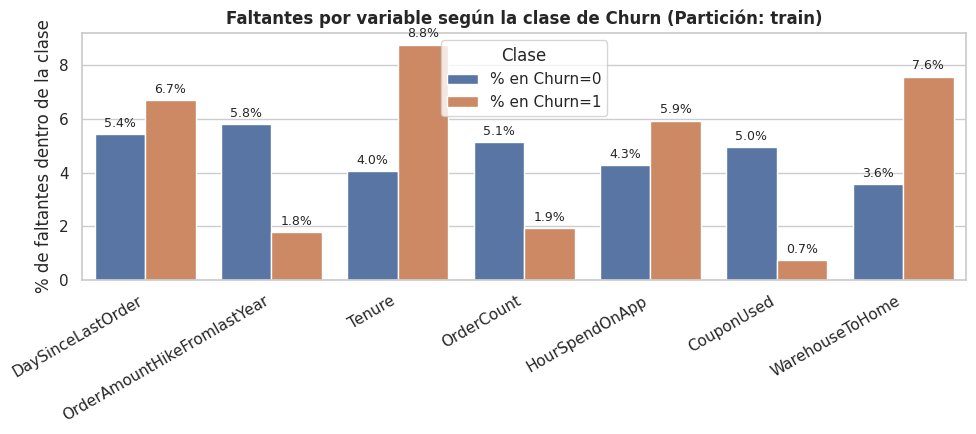

In [ ]:
y = df[TARGET]
resumen_na = pd.DataFrame({
    "n_faltantes": df[cols_na].isna().sum(),
    "% faltante": (100 * df[cols_na].isna().mean()).round(2)
})
resumen_na["% en Churn=0"] = [round(100 * df.loc[y == 0, c].isna().mean(), 2) for c in resumen_na.index]
resumen_na["% en Churn=1"] = [round(100 * df.loc[y == 1, c].isna().mean(), 2) for c in resumen_na.index]
resumen_na = resumen_na.sort_values("% faltante", ascending=False)
display(resumen_na)
exportar(resumen_na, "02_faltantes_resumen")

n_na_fila = df[cols_na].isna().sum(axis=1)
tiene_na = n_na_fila > 0
print(f"Total de celdas faltantes en {EDA_SOBRE}: {int(n_na_fila.sum())}")
print(f"Filas con al menos un faltante: {int(tiene_na.sum())} ({tiene_na.mean():.2%}) | Filas completas: {int((~tiene_na).sum())}")
print(f"Distribución del número de NaNs por fila: {n_na_fila.value_counts().to_dict()}")

fig, ax = plt.subplots(figsize=(10, 4.5))
largo = resumen_na[["% en Churn=0", "% en Churn=1"]].reset_index().melt(
    id_vars="index", var_name="Clase", value_name="% faltante"
)
sns.barplot(data=largo, x="index", y="% faltante", hue="Clase", palette=[COLORES[0], COLORES[1]], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, padding=3)

ax.set_xlabel("")
ax.set_ylabel("% de faltantes dentro de la clase")
ax.set_title(f"Faltantes por variable según la clase de Churn (Partición: {EDA_SOBRE})", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

guardar(fig, "02_faltantes_por_clase")

plt.show()

A partir de estos resultados observamos que 1.351 registros presentan exactamente un valor faltante, mientras que los 2.707 restantes tienen información completa. Ningún registro presenta más de un dato faltante. También encontramos diferencias en la proporción de valores ausentes entre las clases de Churn, lo que justifica estudiar si estos patrones aportan información relevante para el modelado.

### 2.2 Asociación de la Ausencia con `Churn`: Prueba $\chi^2$, *Forest Plot* de *Odds Ratios* y Compensación de Efectos


Se evalúa la asociación entre la ausencia de cada variable y Churn mediante tablas de contingencia, prueba Chi-cuadrado, Odds Ratio (OR), intervalos de confianza del 95 % y corrección de Benjamini-Hochberg.

Los resultados muestran cinco variables con asociaciones estadísticamente significativas después del ajuste:
- **OR > 1:** Tenure y WarehouseToHome presentan mayores momios observados de abandono cuando falta su información.
- **OR < 1:** OrderCount, OrderAmountHikeFromlastYear y CouponUsed presentan menores momios observados de abandono cuando falta su información.

HourSpendOnApp y DaySinceLastOrder no presentan asociaciones estadísticamente significativas después del ajuste.

Estas asociaciones deben interpretarse con precaución, ya que posteriormente se identificó que los valores faltantes están concentrados en rangos específicos de CashbackAmount. Por tanto, los Odds Ratios no representan un efecto causal de la ausencia de información sobre el abandono.


,n_ausentes,churn_si_ausente_%,churn_si_presente_%,dif_pp,OR,IC95_inf,IC95_sup,chi2,p,q_BH,asociada_a_churn
variable,,,,,,,,,,,
Tenure,196,30.1,15.9,14.2,2.29,1.67,3.14,26.18,3.102346e-07,0.000002,SÍ
WarehouseToHome,172,29.7,16.0,13.6,2.22,1.59,3.11,21.19,4.154754e-06,0.000010,SÍ
HourSpendOnApp,185,21.6,16.3,5.3,1.42,0.99,2.04,3.18,7.437171e-02,0.086767,no
DaySinceLastOrder,229,19.7,16.4,3.2,1.26,0.90,1.76,1.42,2.329514e-01,0.232951,no
OrderCount,187,7.0,17.0,-10.1,0.38,0.21,0.66,12.43,4.228119e-04,0.000592,SÍ
OrderAmountHikeFromlastYear,209,5.7,17.2,-11.4,0.31,0.17,0.54,17.91,2.317163e-05,0.000041,SÍ
CouponUsed,173,2.9,17.2,-14.3,0.16,0.07,0.37,23.47,1.266645e-06,0.000004,SÍ


=== DEMOSTRACIÓN DE LA COMPENSACIÓN DE EFECTOS A NIVEL DE FILA ===
• Tasa de Churn en clientes con 1 dato faltante: 16.65%
• Tasa de Churn en clientes sin datos faltantes: 16.55%
• Prueba Chi-cuadrado agregada: chi2 = 0.002, p = 0.968 (No significativa)
Conclusión técnica: Como la ausencia en 'WarehouseToHome'/'Tenure' se asocia a un mayor Churn (OR > 2.2)
 y en 'CouponUsed'/'OrderAmountHike'/'OrderCount' se asocia a una reducción (OR < 0.40), agregarlos en una sola bandera booleana ('tiene_na') compensa ambos efectos opuestos.
Por tanto, se recomienda usar indicadores de ausencia individuales por columna en lugar de una bandera global.



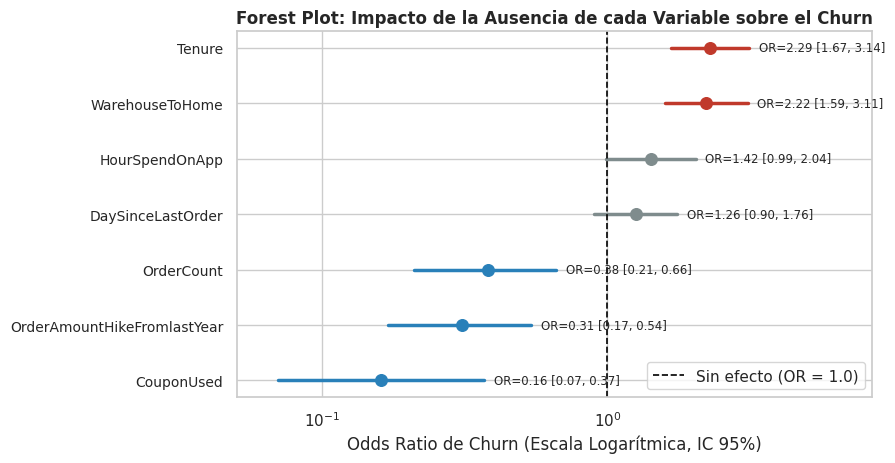

In [ ]:
filas = []
for c in cols_na:
    m = df[c].isna()
    t = pd.crosstab(m, y).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    chi2, p = stats.chi2_contingency(t)[:2]
    a, b = t.loc[True, 1], t.loc[True, 0]     # Ausente: Churn=1 / Churn=0
    cc, d = t.loc[False, 1], t.loc[False, 0]  # Presente: Churn=1 / Churn=0
    orr = ((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (cc + 0.5))
    se = np.sqrt(1 / (a + 0.5) + 1 / (b + 0.5) + 1 / (cc + 0.5) + 1 / (d + 0.5))
    filas.append({
        "variable": c, "n_ausentes": int(a + b),
        "churn_si_ausente_%": round(100 * a / (a + b), 1),
        "churn_si_presente_%": round(100 * cc / (cc + d), 1),
        "dif_pp": round(100 * (a / (a + b) - cc / (cc + d)), 1),
        "OR": round(orr, 2),
        "IC95_inf": round(np.exp(np.log(orr) - 1.96 * se), 2),
        "IC95_sup": round(np.exp(np.log(orr) + 1.96 * se), 2),
        "chi2": round(chi2, 2), "p": p
    })

tabla_na_churn = pd.DataFrame(filas).set_index("variable")
tabla_na_churn["q_BH"] = bh(tabla_na_churn["p"].values)
tabla_na_churn["asociada_a_churn"] = np.where(tabla_na_churn["q_BH"] < ALPHA, "SÍ", "no")
tabla_na_churn = tabla_na_churn.sort_values("OR", ascending=False)
display(tabla_na_churn)
exportar(tabla_na_churn, "02_faltantes_vs_churn")

# Demostración de la Compensación de Efectos al colapsar los indicadores en una sola bandera por fila
chi2_f, p_f = stats.chi2_contingency(pd.crosstab(tiene_na, y))[:2]
print("=== DEMOSTRACIÓN DE LA COMPENSACIÓN DE EFECTOS A NIVEL DE FILA ===")
print(f"• Tasa de Churn en clientes con 1 dato faltante: {100 * y[tiene_na].mean():.2f}%")
print(f"• Tasa de Churn en clientes sin datos faltantes: {100 * y[~tiene_na].mean():.2f}%")
print(f"• Prueba Chi-cuadrado agregada: chi2 = {chi2_f:.3f}, p = {p_f:.3f} (No significativa)")
print("Conclusión técnica: Como la ausencia en 'WarehouseToHome'/'Tenure' se asocia a un mayor Churn (OR > 2.2)\n y en 'CouponUsed'/'OrderAmountHike'/'OrderCount' se asocia a una reducción (OR < 0.40), agregarlos en una sola bandera booleana ('tiene_na') compensa ambos efectos opuestos.\nPor tanto, se recomienda usar indicadores de ausencia individuales por columna en lugar de una bandera global.\n")

# Forest Plot de Odds Ratios (Escala Logarítmica)
fig, ax = plt.subplots(figsize=(9, 4.8))
y_pos = np.arange(len(tabla_na_churn))
ors = tabla_na_churn["OR"].values
ic_inf = tabla_na_churn["IC95_inf"].values
ic_sup = tabla_na_churn["IC95_sup"].values
colores_or = ["#c0392b" if (o > 1 and q < ALPHA) else ("#2980b9" if (o < 1 and q < ALPHA) else "#7f8c8d")
              for o, q in zip(ors, tabla_na_churn["q_BH"])]

for i in range(len(tabla_na_churn)):
    ax.plot([ic_inf[i], ic_sup[i]], [y_pos[i], y_pos[i]], color=colores_or[i], lw=2.5)
    ax.scatter(ors[i], y_pos[i], color=colores_or[i], s=70, zorder=3)
    ax.text(ic_sup[i] * 1.08, y_pos[i], f"OR={ors[i]:.2f} [{ic_inf[i]:.2f}, {ic_sup[i]:.2f}]", va="center", fontsize=8.5)

ax.axvline(1.0, color="black", linestyle="--", lw=1.2, label="Sin efecto (OR = 1.0)")
ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(tabla_na_churn.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0.05, 8.5)
ax.set_xlabel("Odds Ratio de Churn (Escala Logarítmica, IC 95%)")
ax.set_title("Forest Plot: Impacto de la Ausencia de cada Variable sobre el Churn", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
guardar(fig, "02_forest_plot_odds_ratio_faltantes")
plt.show()


Los resultados muestran que la ausencia de información presenta diferentes asociaciones con Churn dependiendo de la variable analizada. Sin embargo, estas diferencias deben interpretarse considerando el patrón de ausencia identificado posteriormente: los valores faltantes se concentran en rangos específicos de CashbackAmount. Al agrupar todos los indicadores de ausencia, las tasas de abandono son prácticamente iguales entre los clientes con y sin datos faltantes (16,65 % y 16,55 %, respectivamente). Por ello, conservaremos indicadores individuales de ausencia durante el preprocesamiento, sin interpretar los Odds Ratios como efectos causales sobre el abandono.

### 2.3 Patrón Estructural de Ausencia: Exclusión Mutua por Fila

Al inspeccionar la matriz de nulidad y la correlación $\phi$ entre indicadores binarios de ausencia, se verifica una propiedad estructural del dataset: **ningún registro presenta más de un valor faltante a la vez** (`n_na_fila` toma únicamente los valores $0$ o $1$). En consecuencia, los indicadores de ausencia tienen correlación ligeramente negativa constante ($\phi \approx -0.05$) entre todos los pares de variables.

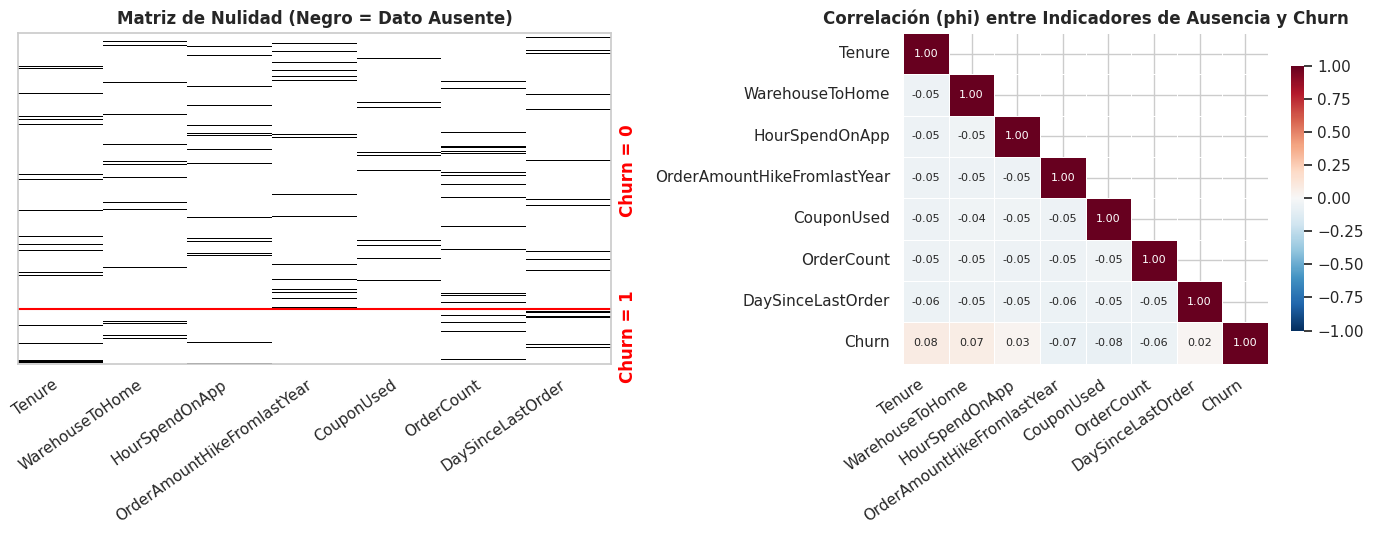

In [ ]:
orden = df.sort_values(TARGET).index
M = df.loc[orden, cols_na].isna().values
n0 = int((y == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.imshow(M, aspect="auto", cmap="Greys", interpolation="nearest")
ax.grid(False)
ax.axhline(n0 - 0.5, color="red", lw=1.5)
ax.set_xticks(range(len(cols_na)))
ax.set_xticklabels(cols_na, rotation=35, ha="right")
ax.set_yticks([])
ax.text(len(cols_na) - 0.4, n0 / 2, "Churn = 0", rotation=90, va="center", color="red", fontweight="bold")
ax.text(len(cols_na) - 0.4, n0 + (len(df) - n0) / 2, "Churn = 1", rotation=90, va="center", color="red", fontweight="bold")
ax.set_title("Matriz de Nulidad (Negro = Dato Ausente)", fontweight="bold")

ind = df[cols_na].isna().astype(int)
ind_churn = ind.assign(Churn=y.values)
corr_na = ind_churn.corr()
sns.heatmap(
    corr_na, mask=np.triu(np.ones(corr_na.shape, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[1]
)
axes[1].set_title("Correlación (phi) entre Indicadores de Ausencia y Churn", fontweight="bold")
plt.setp(axes[1].get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "02_patron_de_ausencia")

plt.show()

A partir de estos gráficos podemos confirmar visualmente algo muy inusual: los datos faltantes están perfectamente separados. Si a un cliente le falta un dato, podemos estar completamente seguros de que no le falta ningún otro. La matriz en tonos grises y la correlación negativa constante nos demuestran que no existen "combos" de datos vacíos. Este comportamiento tan exacto y artificial nos da la pista clave para sospechar que la información no se perdió por simple azar, preparando el terreno para el descubrimiento de la siguiente sección.

### 2.4 Diagnóstico del Mecanismo de Ausencia (MCAR vs. MAR) Libre de Fugas

Para evaluar si la probabilidad de que falte una variable depende de las características observadas del cliente (**MAR**, *Missing At Random*), entrenamos un clasificador `HistGradientBoostingClassifier` bajo validación cruzada estratificada de 5 pliegues para predecir cada indicador `df[c].isna()` utilizando **exclusivamente variables 100% completas** (`columnas_completas`), garantizando que ningún indicador de ausencia ni variable con nulos se filtre en el conjunto de predictores:

- **ROC-AUC cercano a 0.50:** No se observa una capacidad importante para predecir la ausencia mediante las variables observadas.
- **ROC-AUC claramente superior a 0.50:** La ausencia puede predecirse utilizando información observada, lo que es compatible con un patrón MAR, aunque no constituye una demostración definitiva del mecanismo.
- **Incremento al incluir Churn:** Permite observar si la variable objetivo aporta información adicional para predecir la ausencia.

In [ ]:
# Selección estricta de variables con 0 valores faltantes en todo el conjunto de datos
columnas_completas = [c for c in df.columns if c != TARGET and not df[c].isna().any()]
assert not df[columnas_completas].isna().any().any(), "Error: Existen nulos en columnas_completas"

print(f"Predictores 100% completos utilizados ({len(columnas_completas)}): {columnas_completas}\n")

Xd_completas = pd.get_dummies(
    df[columnas_completas],
    columns=[c for c in nom_cols if c in columnas_completas],
    dtype=float
)

cv_mar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Modelo regularizado para estimar dependencia estructural real (evita memorización de duplicados)
mdl_mar = HistGradientBoostingClassifier(max_depth=3, min_samples_leaf=30, max_iter=100, random_state=SEED)

filas_mar = []
for c in cols_na:
    t_na = df[c].isna().astype(int)
    X_sin = Xd_completas.copy()
    X_con = X_sin.assign(Churn=y.values)

    auc_sin = cross_validate(mdl_mar, X_sin, t_na, cv=cv_mar, scoring="roc_auc")["test_score"].mean()
    auc_con = cross_validate(mdl_mar, X_con, t_na, cv=cv_mar, scoring="roc_auc")["test_score"].mean()

    filas_mar.append({
        "variable": c,
        "AUC sin Churn (MAR)": round(auc_sin, 3),
        "AUC con Churn": round(auc_con, 3),
        "Delta AUC (Churn)": round(auc_con - auc_sin, 3),
        "Patrón observado": (
        "Alta dependencia de variables observadas"
        if auc_sin >= 0.70
        else "Dependencia moderada de variables observadas"
        if auc_sin >= 0.58
        else "Sin evidencia clara de dependencia"
      )
    })

mar_tabla = pd.DataFrame(filas_mar).set_index("variable").sort_values("AUC sin Churn (MAR)", ascending=False)
display(mar_tabla)
exportar(mar_tabla, "02_diagnostico_mecanismo_mar")

print("\n=== ANÁLISIS DE BLOQUES POR CASHBACKAMOUNT ===")
filas = []
for c in cols_na:
    m = df[c].isna()
    lo, hi = df.loc[m, "CashbackAmount"].agg(["min", "max"])
    banda = df["CashbackAmount"].between(lo, hi)
    filas.append({"variable": c, "cashback_min": lo, "cashback_max": hi,
                  "filas_en_banda": int(banda.sum()), "NaN_en_banda": int((m & banda).sum()),
                  "churn_banda_%": round(100 * y[banda].mean(), 1)})

display(pd.DataFrame(filas).set_index("variable").sort_values("cashback_min"))

Predictores 100% completos utilizados (11): ['PreferredLoginDevice', 'CityTier', 'PreferredPaymentMode', 'Gender', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'CashbackAmount']



,AUC sin Churn (MAR),AUC con Churn,Delta AUC (Churn),Patrón observado
variable,,,,
Tenure,1.0,1.0,-0.0,Alta dependencia de variables observadas
WarehouseToHome,1.0,1.0,0.0,Alta dependencia de variables observadas
HourSpendOnApp,1.0,1.0,0.0,Alta dependencia de variables observadas
OrderAmountHikeFromlastYear,1.0,1.0,0.0,Alta dependencia de variables observadas
CouponUsed,1.0,1.0,0.0,Alta dependencia de variables observadas
OrderCount,1.0,1.0,0.0,Alta dependencia de variables observadas
DaySinceLastOrder,1.0,1.0,0.0,Alta dependencia de variables observadas



=== ANÁLISIS DE BLOQUES POR CASHBACKAMOUNT ===


,cashback_min,cashback_max,filas_en_banda,NaN_en_banda,churn_banda_%
variable,,,,,
Tenure,112.00,123.13,198,196,30.3
WarehouseToHome,123.18,126.57,172,172,29.7
HourSpendOnApp,126.62,131.61,185,185,21.6
DaySinceLastOrder,209.32,231.20,229,229,19.7
OrderCount,231.85,260.70,188,187,6.9
CouponUsed,261.03,291.90,174,173,2.9
OrderAmountHikeFromlastYear,292.04,322.40,209,209,5.7



Los resultados muestran un patrón estructurado de datos faltantes asociado a CashbackAmount. Al analizar los rangos de esta variable, encontramos que prácticamente todos los registros ubicados en dichos segmentos presentan ausencia en una característica específica. Esto explica el AUC de 1,000 obtenido al predecir los indicadores de ausencia utilizando las variables observadas.

El comportamiento encontrado es compatible con un mecanismo MAR, ya que la ausencia puede explicarse mediante una variable observada: CashbackAmount. No obstante, no contamos con información adicional sobre el proceso original de generación de los datos para determinar cómo se produjo este patrón.

Este hallazgo también permite interpretar correctamente los Odds Ratios anteriores: reflejan diferencias entre los rangos de CashbackAmount y no un efecto directo de los valores faltantes sobre Churn. Además, como dentro de esos rangos existen pocos valores observados, la imputación representa una estimación con información limitada. Por esta razón consideramos importante conservar indicadores individuales de ausencia durante el modelado.

### 2.5 Concentración de Datos Faltantes por Segmentos Categóricos

Evaluamos la intensidad de asociación (V de Cramér corregida) entre el indicador de ausencia de cada variable y las variables categóricas/ordinales, **excluyendo la propia variable cuando se evalúa `HourSpendOnApp`** para evitar tautologías estadísticas.

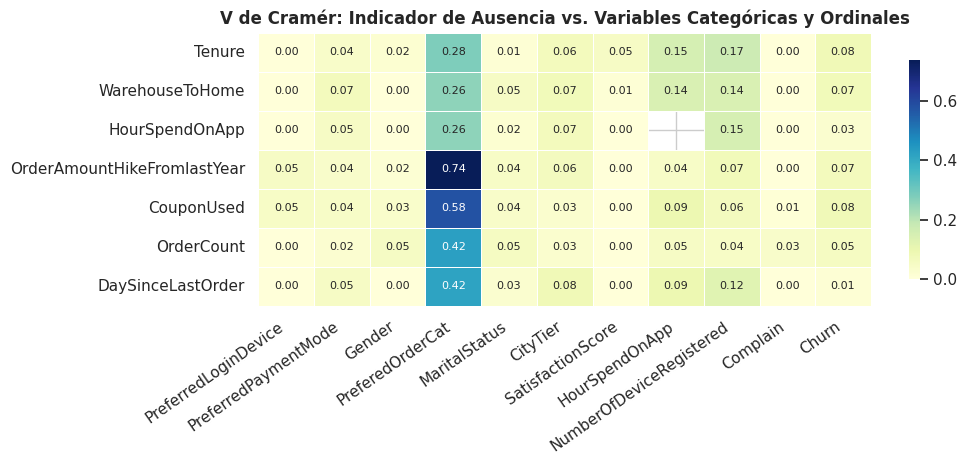

,variable_faltante,segmento,n,% faltante,% base,lift,p,q_BH
0,OrderAmountHikeFromlastYear,PreferedOrderCat = Others,200,72.50,5.15,14.08,7.070223e-139,1.859469e-136
1,CouponUsed,PreferedOrderCat = Grocery,290,43.45,4.26,10.19,1.437476e-91,1.890282e-89
2,DaySinceLastOrder,PreferedOrderCat = Fashion,612,28.27,5.64,5.01,6.787976e-71,5.950792e-69
3,OrderCount,PreferedOrderCat = Grocery,290,27.93,4.61,6.06,6.846970e-40,4.501883e-38
4,DaySinceLastOrder,PreferedOrderCat = Mobile Phone,1495,0.00,5.64,0.00,3.249424e-38,1.709197e-36
5,OrderAmountHikeFromlastYear,PreferedOrderCat = Mobile Phone,1495,0.00,5.15,0.00,7.229674e-35,3.169007e-33
6,OrderAmountHikeFromlastYear,PreferedOrderCat = Laptop & Accessory,1461,0.00,5.15,0.00,5.043714e-34,1.894995e-32
7,Tenure,PreferedOrderCat = Mobile Phone,1495,12.71,4.83,2.63,6.620652e-33,2.176539e-31
8,OrderCount,PreferedOrderCat = Fashion,612,17.32,4.61,3.76,1.649943e-31,4.821499e-30
9,OrderCount,PreferedOrderCat = Mobile Phone,1495,0.00,4.61,0.00,5.334051e-31,1.402856e-29


Segmentos estadísticamente significativos (q_BH < 0.05): 88 de 263 evaluados (33.5%)


In [ ]:
seg_vars = nom_cols + ord_cols + bin_cols + [TARGET]

# (a) Matriz V de Cramér entre cada indicador de ausencia y cada variable de segmentación
V_na = pd.DataFrame(index=cols_na, columns=seg_vars, dtype=float)
for c in cols_na:
    for g in seg_vars:
        # Evitar comparar el indicador de ausencia de HourSpendOnApp consigo misma
        if c == g:
            V_na.loc[c, g] = np.nan
        else:
            V_na.loc[c, g] = cramers_v(ind[c], df[g])

fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.heatmap(
    V_na, cmap="YlGnBu", vmin=0, vmax=max(0.1, float(np.nanmax(V_na.values))),
    annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("V de Cramér: Indicador de Ausencia vs. Variables Categóricas y Ordinales", fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "02_V_ausencia_vs_categoricas")
plt.show()

# (b) Prueba binomial exacta por segmento frente a la tasa base de ausencia de cada variable
filas_seg = []
for c in cols_na:
    m = df[c].isna()
    base = m.mean()
    for g in seg_vars:
        if c == g:
            continue  # Excluir auto-segmentación tautológica
        for cat, sub in df.groupby(g, dropna=True):
            n = len(sub)
            k = int(m.loc[sub.index].sum())
            if n >= 80 and base > 0:
                filas_seg.append({
                    "variable_faltante": c, "segmento": f"{g} = {cat}", "n": n,
                    "% faltante": round(100 * k / n, 2), "% base": round(100 * base, 2),
                    "lift": round((k / n) / base, 2), "p": stats.binomtest(k, n, base).pvalue
                })

seg_df = pd.DataFrame(filas_seg)
seg_df["q_BH"] = bh(seg_df["p"].values)
n_sig_seg = int((seg_df["q_BH"] < ALPHA).sum())
total_seg = len(seg_df)

display(seg_df.sort_values("p").head(12).reset_index(drop=True))
print(f"Segmentos estadísticamente significativos (q_BH < {ALPHA}): {n_sig_seg} de {total_seg} evaluados ({n_sig_seg/total_seg:.1%})")
exportar(seg_df.sort_values("p"), "02_faltantes_segmentos")

A partir de este análisis cruzado, evaluamos si la falta de información se concentra de manera inusual en ciertos perfiles o grupos de clientes (por ejemplo, si faltan más datos en quienes compran en cierta categoría o pagan con un método específico). Gracias a las pruebas estadísticas y al mapa de calor, podemos identificar estas relaciones. Sin embargo, conectando esto con el hallazgo de la celda anterior, cualquier asociación fuerte que detectemos aquí (como podría ser con la categoría de compra PreferedOrderCat) es en realidad un "espejo" o efecto secundario (proxy) de los bloques de CashbackAmount. Es decir, la información falta por los rangos de dinero devuelto, y esos rangos coinciden casualmente con ciertas categorías de clientes.

## 3. Análisis Univariado Integral (Continuas, Discretas de Conteo y Categóricas)

Se analizan **todas** las variables predictoras agrupadas según su naturaleza:
1. **Variables Continuas (`cont_cols`):** Estadísticos descriptivos, asimetría, curtosis, detección de *outliers* e inspección de distribuciones (Histogramas de densidad, Boxplots y Curvas ECDF por clase de `Churn`).
2. **Variables Discretas de Conteo (`disc_cols`):** `NumberOfAddress`, `OrderAmountHikeFromlastYear`, `CouponUsed` y `OrderCount` evaluando su distribución y tasa de abandono condicional.
3. **Variables Categóricas, Ordinales y Binarias (`cat_vars`):** Tasas de `Churn` por categoría frente a la tasa base de entrenamiento.

In [ ]:
print("=== 3.1 ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS (CONTINUAS Y DISCRETAS DE CONTEO) ===")
desc = df[num_cols].describe(percentiles=[0.25, 0.50, 0.75]).T
desc["tipo"] = ["Continua" if c in cont_cols else "Discreta (Conteo)" for c in desc.index]
desc["asimetría"] = df[num_cols].skew()
desc["curtosis"] = df[num_cols].kurt()
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
desc["outliers_IQR"] = ((df[num_cols] < (q1 - 1.5 * iqr)) | (df[num_cols] > (q3 + 1.5 * iqr))).sum()
desc["% outliers"] = (100 * desc["outliers_IQR"] / desc["count"]).round(2)

cols_orden_desc = ["tipo", "count", "mean", "std", "min", "25%", "50%", "75%", "max", "asimetría", "curtosis", "outliers_IQR", "% outliers"]
desc = desc[cols_orden_desc]
display(desc.round(2))
exportar(desc.round(3), "03_univariado_numericas_completo")

# Auditoría específica de valores extremos de dominio (errores de captura potenciales)
print("\n=== AUDITORÍA DE EXTREMOS DE DOMINIO (VALORES ATÍPICOS PUNTUALES) ===")
print(f"• Tenure > 31 meses: {int((df['Tenure'] > 31).sum())} registros (valores observados: {sorted(df.loc[df['Tenure'] > 31, 'Tenure'].dropna().unique())})")
print(f"• WarehouseToHome > 40 km: {int((df['WarehouseToHome'] > 40).sum())} registros (valores observados: {sorted(df.loc[df['WarehouseToHome'] > 40, 'WarehouseToHome'].dropna().unique())})")
print(f"• NumberOfAddress > 11 direcciones: {int((df['NumberOfAddress'] > 11).sum())} registros (valores observados: {sorted(df.loc[df['NumberOfAddress'] > 11, 'NumberOfAddress'].dropna().unique())})")

=== 3.1 ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS (CONTINUAS Y DISCRETAS DE CONTEO) ===


,tipo,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis,outliers_IQR,% outliers
Tenure,Continua,3862.0,10.29,8.56,0.0,2.00,9.00,16.00,61.00,0.71,-0.10,3,0.08
WarehouseToHome,Continua,3886.0,15.52,8.50,5.0,9.00,13.00,20.00,127.00,1.44,7.15,1,0.03
DaySinceLastOrder,Continua,3829.0,4.58,3.65,0.0,2.00,3.00,7.00,46.00,1.18,4.40,48,1.25
CashbackAmount,Continua,4058.0,177.82,49.90,0.0,145.84,163.84,198.14,324.99,1.13,0.95,313,7.71
NumberOfAddress,Discreta (Conteo),4058.0,4.21,2.57,1.0,2.00,3.00,6.00,22.00,1.10,1.10,3,0.07
OrderAmountHikeFromlastYear,Discreta (Conteo),3849.0,15.72,3.66,11.0,13.00,15.00,18.00,26.00,0.78,-0.30,21,0.55
CouponUsed,Discreta (Conteo),3885.0,1.80,1.95,0.0,1.00,1.00,2.00,16.00,2.52,8.80,476,12.25
OrderCount,Discreta (Conteo),3871.0,3.11,3.03,1.0,1.00,2.00,3.00,16.00,2.13,4.31,540,13.95



=== AUDITORÍA DE EXTREMOS DE DOMINIO (VALORES ATÍPICOS PUNTUALES) ===
• Tenure > 31 meses: 3 registros (valores observados: [np.float64(50.0), np.float64(51.0), np.float64(61.0)])
• WarehouseToHome > 40 km: 1 registros (valores observados: [np.float64(127.0)])
• NumberOfAddress > 11 direcciones: 3 registros (valores observados: [np.int64(19), np.int64(21), np.int64(22)])


De esta tabla estadística extraemos el panorama general de cómo se distribuyen nuestras variables numéricas. Al observar medidas como la media, la mediana (cuartil 50%) y la asimetría, podemos saber si los datos están balanceados o si tienden a acumularse hacia un lado de la gráfica. El punto más importante aquí es la detección de outliers (valores atípicos), los cuales nos muestran registros extremos, como clientes que viven a más de 40 kilómetros de distancia o tienen más de 11 direcciones registradas. Identificar esto es fundamental, ya que modelos predictivos como la Regresión Logística o las Máquinas de Vectores de Soporte (SVM) son sensibles a estos valores inusuales y podrían sesgarse si no aplicamos un tratamiento adecuado durante el preprocesamiento, como el escalado o la estandarización.

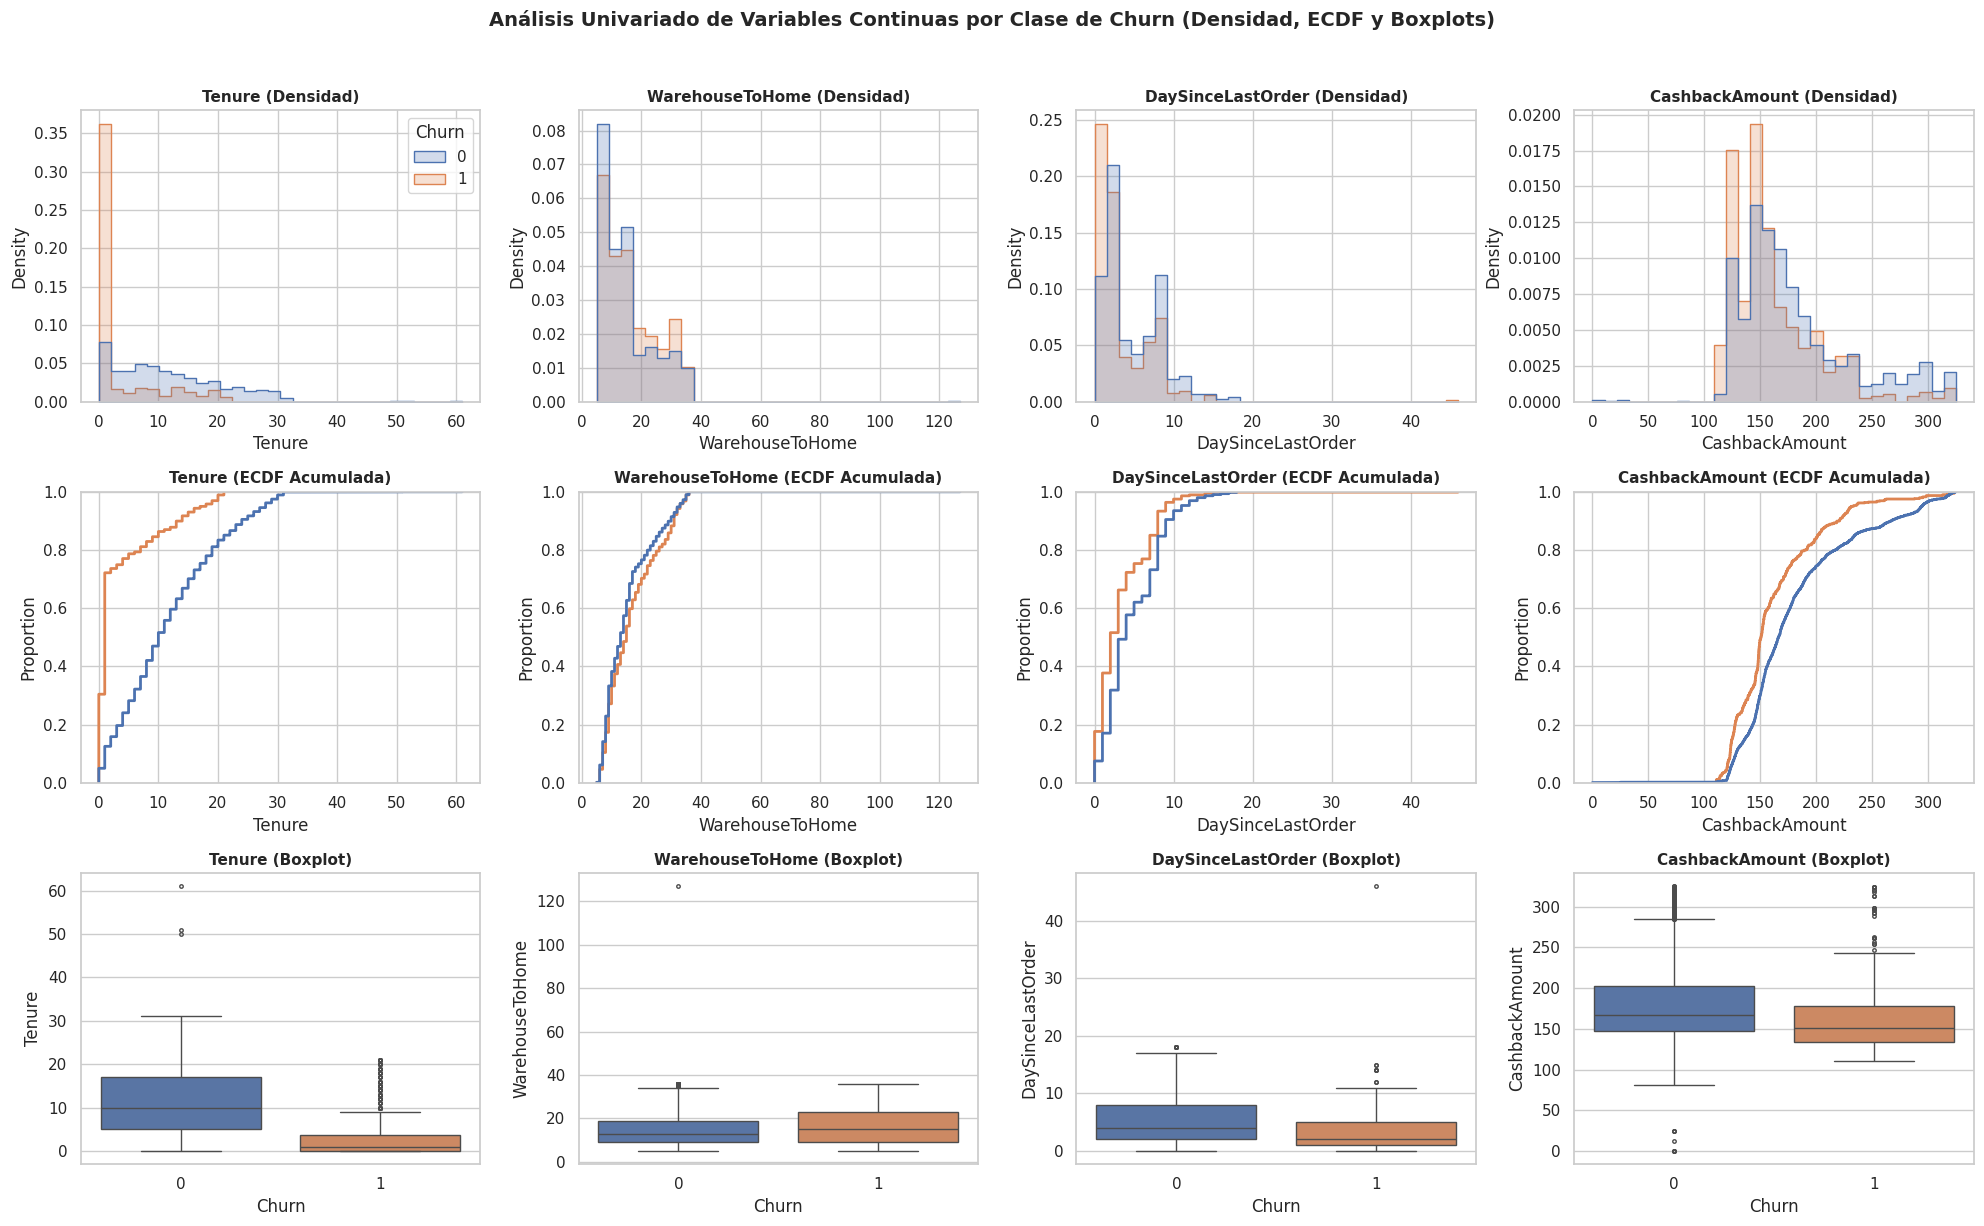

In [ ]:
# Histogramas de densidad y Curvas Acumuladas Empíricas (ECDF) para variables continuas
fig, axes = plt.subplots(3, 4, figsize=(20, 12))

for idx, c in enumerate(cont_cols):
    # Fila 0: Histograma de densidad
    ax_h = axes[0, idx]
    sns.histplot(
        data=df, x=c, hue=TARGET, stat="density", common_norm=False, element="step",
        bins=30, palette=COLORES, ax=ax_h, legend=(idx == 0)
    )
    ax_h.set_title(f"{c} (Densidad)", fontsize=11, fontweight="bold")

    # Fila 1: ECDF (muestra diferencias de estocasticidad y medianas sin sesgo de binning)
    ax_e = axes[1, idx]
    sns.ecdfplot(data=df, x=c, hue=TARGET, palette=COLORES, lw=2, ax=ax_e, legend=False)
    ax_e.set_title(f"{c} (ECDF Acumulada)", fontsize=11, fontweight="bold")

    # Fila 2: Boxplot por clase
    ax_b = axes[2, idx]
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=COLORES, legend=False, ax=ax_b, fliersize=2.5)
    ax_b.set_title(f"{c} (Boxplot)", fontsize=11, fontweight="bold")
    ax_b.set_xlabel("Churn")

fig.suptitle("Análisis Univariado de Variables Continuas por Clase de Churn (Densidad, ECDF y Boxplots)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_continuas_densidad_ecdf_boxplots")
plt.show()

A partir de estas tres gráficas podemos entender el comportamiento profundo de cada variable continua y su relación con la fuga de clientes (Churn). Los histogramas nos muestran la "forma" de los datos y dónde se concentran; las curvas acumuladas (ECDF) nos permiten comparar de forma muy limpia, y sin los sesgos visuales que a veces causan las barras tradicionales, si un grupo de clientes tiende a tener valores más altos o más bajos que el otro. Finalmente, los diagramas de caja (boxplots) nos dan un resumen rápido para comparar las medianas y visualizar de inmediato qué tantos valores extremos (outliers) tiene cada grupo. En conjunto, esto nos indica visualmente qué variables tienen un poder predictivo claro para separar a los clientes que se quedan de los que se van, preparándonos para los algoritmos de clasificación de la siguiente etapa.

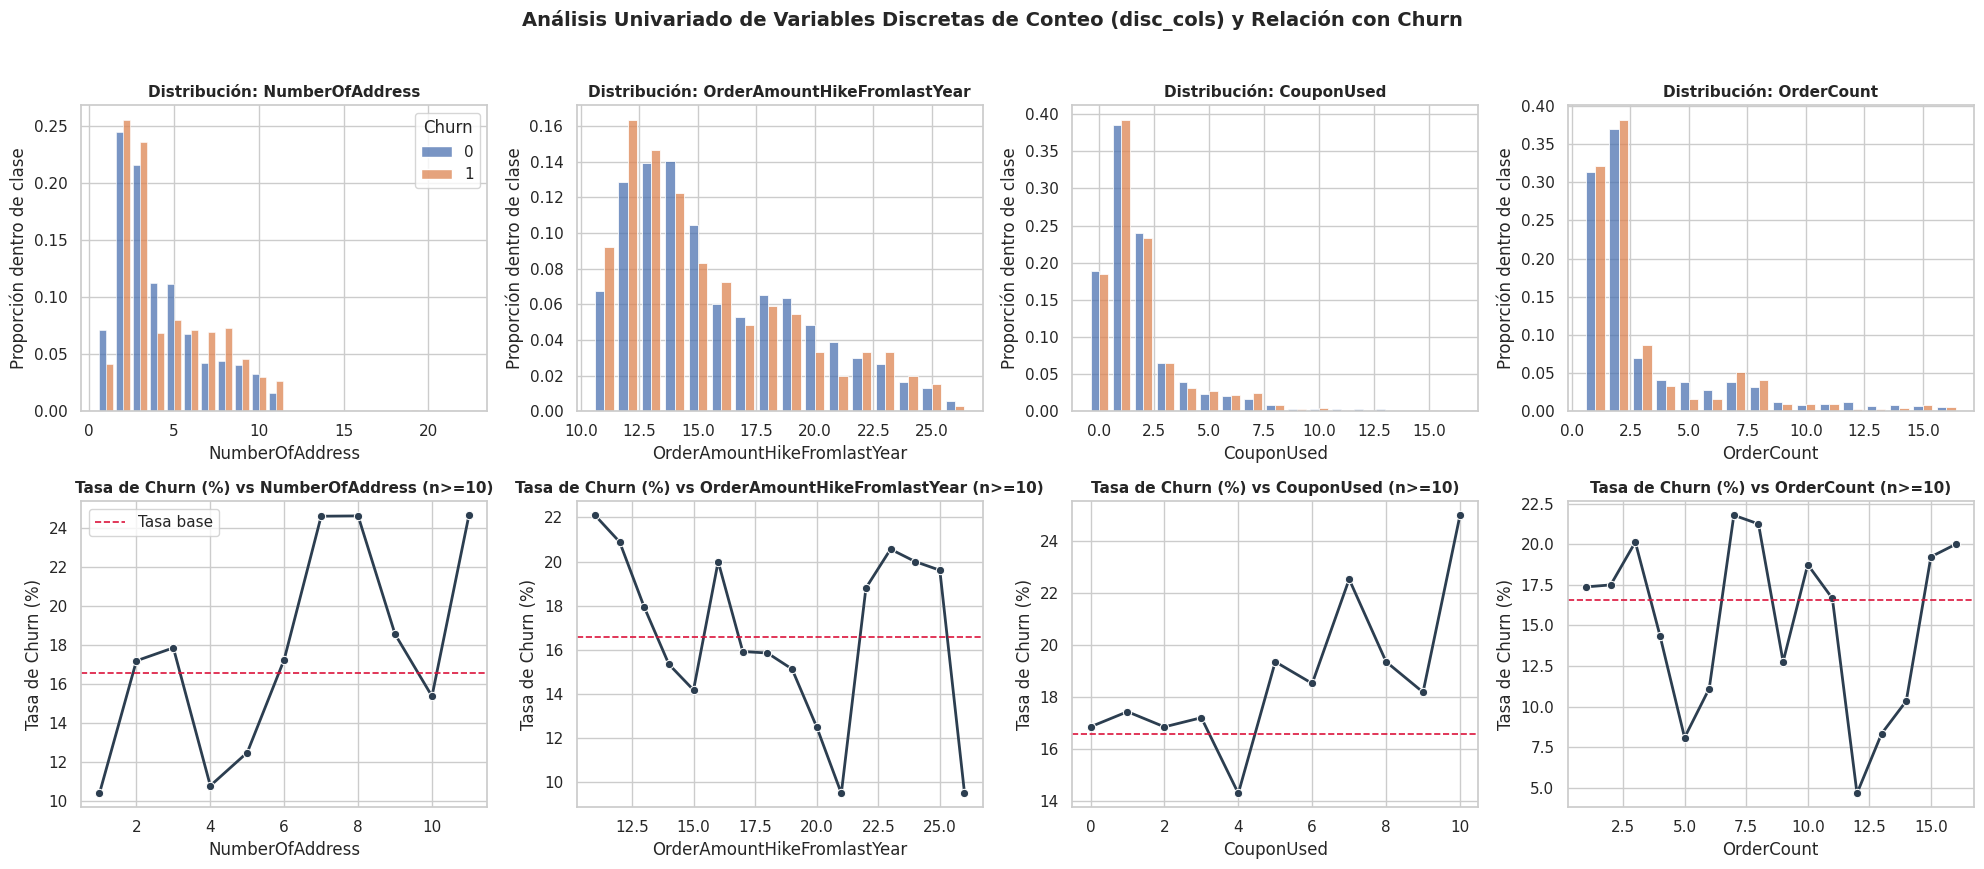

In [ ]:
# Visualización dedicada para las 4 variables discretas de rango amplio (disc_cols)
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))

for idx, c in enumerate(disc_cols):
    # Fila superior: Distribución por clase de Churn
    ax_top = axes[0, idx]
    sns.histplot(
        data=df, x=c, hue=TARGET, stat="probability", common_norm=False,
        discrete=True, element="bars", multiple="dodge", shrink=0.8, palette=COLORES, ax=ax_top, legend=(idx == 0)
    )
    ax_top.set_title(f"Distribución: {c}", fontsize=11, fontweight="bold")
    ax_top.set_ylabel("Proporción dentro de clase")

    # Fila inferior: Tasa de Churn condicional según el valor discreto
    ax_bot = axes[1, idx]
    t_disc = df.groupby(c, dropna=True)[TARGET].agg(n="size", tasa="mean").reset_index()
    t_disc["tasa"] *= 100
    # Filtrar valores con al menos 10 observaciones para estabilidad visual
    t_disc_f = t_disc[t_disc["n"] >= 10]
    sns.lineplot(data=t_disc_f, x=c, y="tasa", marker="o", color="#2c3e50", lw=2, ax=ax_bot)
    ax_bot.axhline(100 * y.mean(), color="crimson", ls="--", lw=1.2, label="Tasa base")
    ax_bot.set_title(f"Tasa de Churn (%) vs {c} (n>=10)", fontsize=11, fontweight="bold")
    ax_bot.set_ylabel("Tasa de Churn (%)")
    if idx == 0:
        ax_bot.legend()

fig.suptitle("Análisis Univariado de Variables Discretas de Conteo (disc_cols) y Relación con Churn", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_discretas_distribucion_y_churn")
plt.show()

Con estas gráficas evaluamos el comportamiento de las variables que se miden en cantidades enteras (como el número de direcciones o los cupones usados). La fila superior nos permite ver cómo se distribuyen estas cantidades comparando a los clientes que se van frente a los que se quedan. La fila inferior es aún más directa: nos dibuja una línea de tendencia que muestra cómo sube o baja la probabilidad exacta de abandono a medida que aumenta la cantidad de la variable, comparándola siempre contra la "tasa base" (el promedio general de abandono). Esto es vital para identificar patrones; por ejemplo, si a partir del tercer cupón usado la probabilidad de irse cae por debajo del promedio, ya tenemos un indicio fuerte de retención que los modelos de Machine Learning podrán aprovechar.

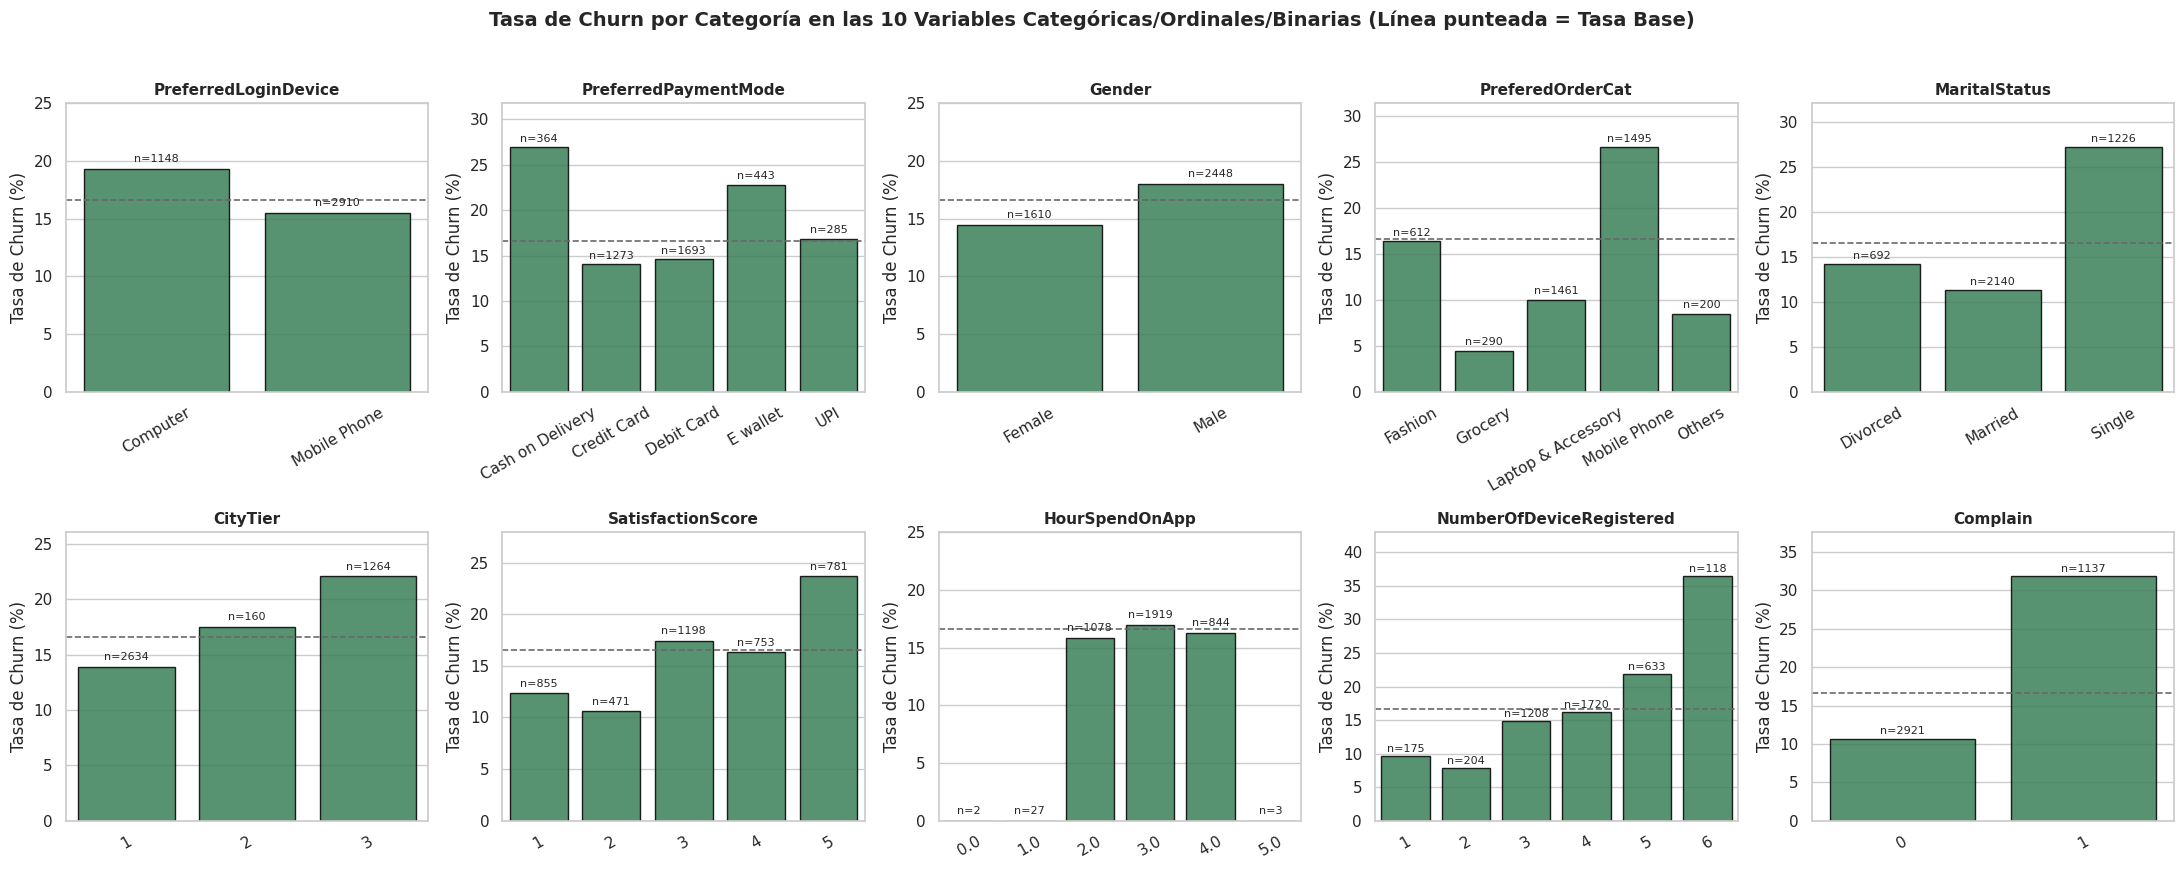

In [ ]:
# Visualización de las 10 variables categóricas, ordinales y binarias
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))

for ax, g in zip(axes.ravel(), cat_vars):
    t = df.groupby(g, dropna=True)[TARGET].agg(["size", "mean"]).reset_index()
    t["mean"] *= 100
    sns.barplot(data=t, x=g, y="mean", color="seagreen", edgecolor="black", alpha=0.85, ax=ax)
    ax.axhline(100 * y.mean(), color="dimgray", ls="--", lw=1.2)
    for i, (n, v) in enumerate(zip(t["size"], t["mean"])):
        ax.text(i, v + 0.6, f"n={n}", ha="center", fontsize=8)
    ax.set_ylabel("Tasa de Churn (%)")
    ax.set_xlabel("")
    ax.set_title(g, fontsize=11, fontweight="bold")
    ax.set_ylim(0, max(t["mean"].max() * 1.18, 25))
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Tasa de Churn por Categoría en las 10 Variables Categóricas/Ordinales/Binarias (Línea punteada = Tasa Base)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_churn_por_categoria_completo")
plt.show()

Estas gráficas de barras nos permiten comparar el riesgo de abandono entre los distintos perfiles de clientes, divididos por sus características cualitativas (como su método de pago preferido, género o nivel de satisfacción). La altura de cada barra nos indica exactamente qué porcentaje de clientes en esa categoría abandonó la empresa, y la línea punteada nos sirve como ancla visual para identificar rápidamente qué grupos superan la tasa promedio y cuáles son más leales. Además, colocar la cantidad de clientes (n=) encima de cada barra es clave para evitar sacar conclusiones engañosas en categorías que tengan muy pocas personas, lo cual nos ayuda a seleccionar las características más confiables para entrenar los modelos.

## 4. Asociación Global de cada Variable Predictora con `Churn`

Evaluamos las **18 variables predictoras** frente a `Churn`:
- **Categóricas, Ordinales y Binarias (`cat_vars`):** Prueba $\chi^2$ de independencia y tamaño del efecto mediante **V de Cramér corregida**.
- **Numéricas Continuas y Discretas de Conteo (`num_cols`):** Prueba no paramétrica $U$ de **Mann-Whitney** y tamaño del efecto mediante **correlación biserial por rangos** ($r_{rb} = \frac{2U}{n_1 n_0} - 1 \in [-1, 1]$).
- Todos los valores $p$ se ajustan por comparaciones múltiples con **Benjamini-Hochberg ($q_{BH}$)**.

In [ ]:
filas_assoc = []
for g in cat_vars:
    t = pd.crosstab(df[g], y)
    chi2, p = stats.chi2_contingency(t)[:2]
    tasas = df.groupby(g)[TARGET].mean()
    filas_assoc.append({
        "variable": g, "naturaleza": "Categórica/Ordinal", "estadístico": round(chi2, 1), "p": p,
        "tamaño_efecto": round(cramers_v(df[g], y), 3),
        "detalle": f"rango de tasas: {100 * tasas.min():.1f}% a {100 * tasas.max():.1f}%"
    })

for c in num_cols:
    a = df.loc[y == 1, c].dropna()
    b = df.loc[y == 0, c].dropna()
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 2 * U / (len(a) * len(b)) - 1
    tipo_lbl = "Continua" if c in cont_cols else "Discreta (Conteo)"
    filas_assoc.append({
        "variable": c, "naturaleza": tipo_lbl, "estadístico": round(U, 0), "p": p,
        "tamaño_efecto": round(r_rb, 3),
        "detalle": f"mediana churn=1: {a.median():.1f} | churn=0: {b.median():.1f}"
    })

assoc = pd.DataFrame(filas_assoc).set_index("variable")
assoc["q_BH"] = bh(assoc["p"].values)
assoc["abs_efecto"] = assoc["tamaño_efecto"].abs()
assoc = assoc.sort_values("abs_efecto", ascending=False).drop(columns=["abs_efecto"])
display(assoc)
exportar(assoc, "04_asociacion_todas_variables_con_churn")

,naturaleza,estadístico,p,tamaño_efecto,detalle,q_BH
variable,,,,,,
Tenure,Continua,370502.0,1.536336e-135,-0.628,mediana churn=1: 1.0 | churn=0: 10.0,2.765404e-134
DaySinceLastOrder,Continua,739334.0,4.476662e-26,-0.264,mediana churn=1: 2.0 | churn=0: 4.0,1.611598e-25
Complain,Categórica/Ordinal,264.1,2.150561e-59,0.255,rango de tasas: 10.6% a 31.8%,1.935505e-58
CashbackAmount,Continua,860762.0,1.181307e-23,-0.244,mediana churn=1: 150.6 | churn=0: 166.5,3.543920e-23
PreferedOrderCat,Categórica/Ordinal,193.5,9.413292e-41,0.216,rango de tasas: 4.5% a 26.6%,5.647975e-40
MaritalStatus,Categórica/Ordinal,145.1,3.040853e-32,0.188,rango de tasas: 11.3% a 27.2%,1.368384e-31
NumberOfDeviceRegistered,Categórica/Ordinal,66.0,7.086356e-13,0.123,rango de tasas: 7.8% a 36.4%,1.822206e-12
SatisfactionScore,Categórica/Ordinal,52.1,1.299861e-10,0.109,rango de tasas: 10.6% a 23.7%,2.924688e-10
PreferredPaymentMode,Categórica/Ordinal,51.2,1.994299e-10,0.108,rango de tasas: 14.1% a 26.9%,3.988598e-10


En esta sección calculamos qué tan fuerte es la relación matemática entre cada variable y el abandono del cliente (Churn). Debido a que tenemos diferentes tipos de datos (como categorías de texto por un lado y números continuos por el otro), usamos dos pruebas estadísticas distintas para poder medir el impacto de todo en una escala unificada (el "tamaño del efecto"). Al ordenar los resultados, obtenemos un ranking objetivo de las características más importantes. Esta lista es fundamental para la etapa de reducción de dimensionalidad que nos exige el proyecto, ya que nos brinda el criterio base para decidir cuáles variables aportan información clave para los modelos predictivos y cuáles podríamos eliminar por ser estadísticamente irrelevantes.

## 5. Matrices de Correlación y Asociación Multivariada por Tipología

Se construyen las matrices de asociación empleando el estimador apropiado para cada combinación de escalas de medición, **incluyendo tanto las variables continuas como las discretas de conteo**:

| Subsección | Conjunto de Variables | Estimador Estadístico |
| :--- | :--- | :--- |
| **5.1** | Numéricas (`cont_cols + disc_cols`) | Correlación lineal de **Pearson ($r$)** |
| **5.2** | Numéricas (`cont_cols + disc_cols`) | Correlación monotónica de **Spearman ($\rho$)** y **VIF** |
| **5.3** | Categóricas + Ordinales + `Complain` + `Churn` | **V de Cramér corregida** (Simétrica) |
| **5.4** | Categóricas + Ordinales + `Complain` + `Churn` | **U de Theil** (Entropía condicional asimétrica) |
| **5.5** | Categóricas/Ordinales (filas) $\times$ Numéricas (columnas) | **Razón de correlación $\eta$ (Eta)** y análisis de dependencia estructural |

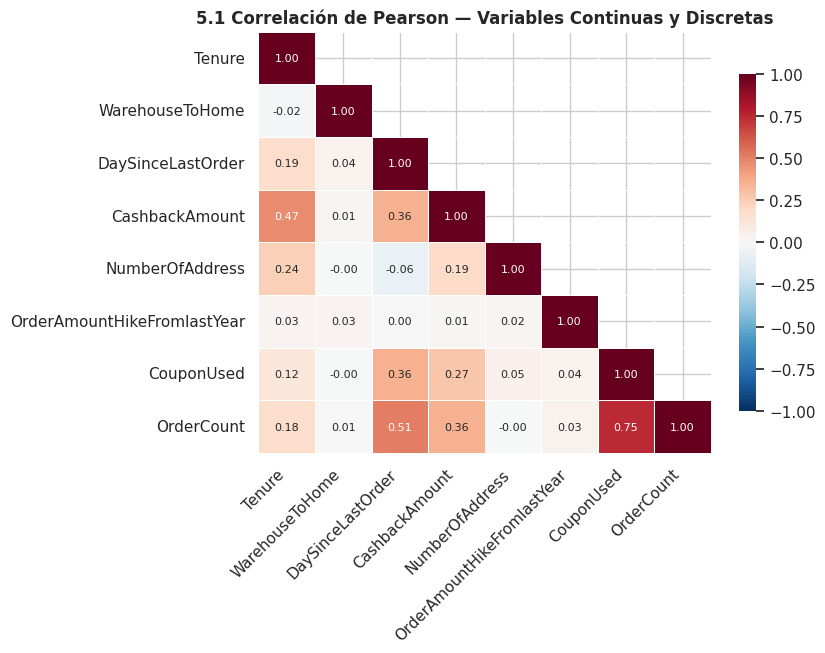

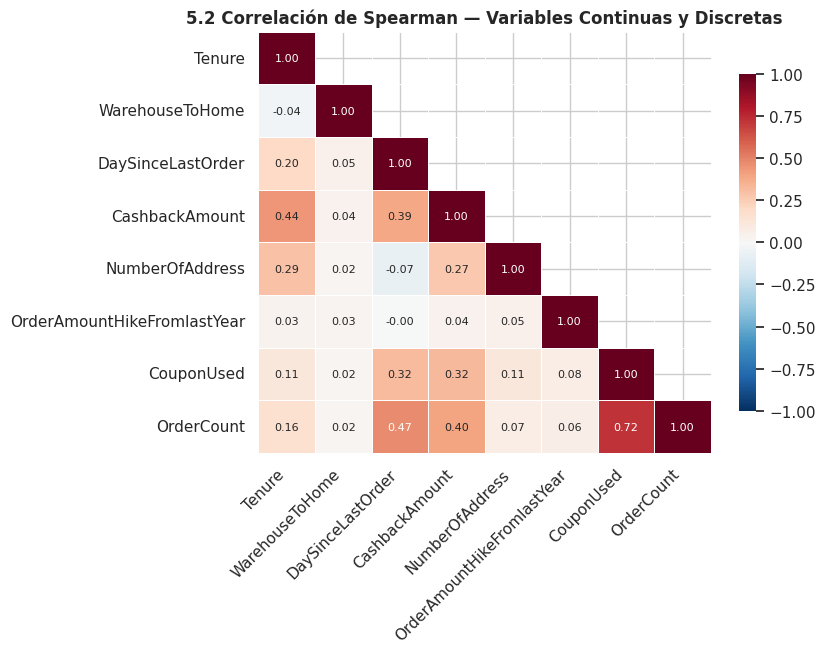

Pares con mayor discrepancia |Pearson - Spearman| (no linealidad o sensibilidad a valores extremos):


|Pearson - Spearman|
CashbackAmount              NumberOfAddress                 0.078
NumberOfAddress             OrderCount                      0.076
                            CouponUsed                      0.063
CashbackAmount              CouponUsed                      0.050
Tenure                      NumberOfAddress                 0.049
OrderAmountHikeFromlastYear CouponUsed                      0.041

Pares numéricos con |rho de Spearman| >= 0.40:


,,rho_Spearman
CouponUsed,OrderCount,0.721
DaySinceLastOrder,OrderCount,0.474
Tenure,CashbackAmount,0.439


,VIF
OrderCount,2.02
CouponUsed,1.76
CashbackAmount,1.46
Tenure,1.32
DaySinceLastOrder,1.32
NumberOfAddress,1.10
WarehouseToHome,1.00
OrderAmountHikeFromlastYear,1.00


Nota: Todos los VIF < 5 confirman ausencia de multicolinealidad lineal severa entre las variables numéricas (máximo en OrderCount y CouponUsed por su relación natural de uso de cupones por pedido).


In [ ]:
pear = df[num_cols].corr(method="pearson")
spear = df[num_cols].corr(method="spearman")

heatmap(pear, "5.1 Correlación de Pearson — Variables Continuas y Discretas", "05_1_pearson")
heatmap(spear, "5.2 Correlación de Spearman — Variables Continuas y Discretas", "05_2_spearman")
exportar(pear.round(3), "05_corr_pearson")
exportar(spear.round(3), "05_corr_spearman")

dif = (pear - spear).abs().where(np.triu(np.ones(pear.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("Pares con mayor discrepancia |Pearson - Spearman| (no linealidad o sensibilidad a valores extremos):")
display(dif.head(6).round(3).to_frame("|Pearson - Spearman|"))

pares_fuertes = spear.where(np.triu(np.ones(spear.shape), k=1).astype(bool)).stack()
pares_fuertes = pares_fuertes[pares_fuertes.abs() >= 0.40].sort_values(key=abs, ascending=False)
print("Pares numéricos con |rho de Spearman| >= 0.40:")
display(pares_fuertes.round(3).to_frame("rho_Spearman") if len(pares_fuertes) else "ninguno")

# Factor de Inflación de la Varianza (VIF) sobre todas las variables numéricas
Z = df[num_cols].fillna(df[num_cols].median())
vif = pd.Series(np.diag(np.linalg.inv(Z.corr().values)), index=num_cols, name="VIF").sort_values(ascending=False)
display(vif.round(2).to_frame())
print("Nota: Todos los VIF < 5 confirman ausencia de multicolinealidad lineal severa entre las variables numéricas (máximo en OrderCount y CouponUsed por su relación natural de uso de cupones por pedido).")

En esta parte analizamos cómo se relacionan las variables numéricas entre sí. Las correlaciones (Pearson y Spearman) nos dicen si dos variables se mueven juntas; por ejemplo, si aumenta la cantidad de pedidos (OrderCount), también tiende a aumentar el uso de cupones (CouponUsed). Spearman suele ser más confiable aquí porque no se deja engañar tan fácil por valores extremos. Además, calculamos el VIF, que es una métrica para detectar "redundancia" (multicolinealidad). Si tuviéramos un VIF muy alto (mayor a 5 o 10), significaría que dos variables nos están dando exactamente la misma información y deberíamos eliminar una para no confundir a nuestros modelos. Como todos nuestros VIF son bajos, comprobamos que cada variable numérica aporta información única y útil, cumpliendo con el requisito de análisis de características para la fase de modelado.

In [ ]:
# NOTA: Se elimina la matriz de Spearman ampliada por ser redundante (marcador QUITAR).
# Se adapta la variable 'rho_churn' extrayendo la información de la tabla 'assoc' de la sección 4
# para asegurar que la síntesis final del notebook se ejecute sin errores.

rho_churn = assoc["tamaño_efecto"].sort_values(key=abs, ascending=False)

print("Fuerza de asociación con Churn (tamaño de efecto extraído de la sección 4):")
display(rho_churn.round(3).to_frame("efecto_con_Churn"))

Fuerza de asociación con Churn (tamaño de efecto extraído de la sección 4):


,efecto_con_Churn
variable,
Tenure,-0.628
DaySinceLastOrder,-0.264
Complain,0.255
CashbackAmount,-0.244
PreferedOrderCat,0.216
MaritalStatus,0.188
NumberOfDeviceRegistered,0.123
SatisfactionScore,0.109
PreferredPaymentMode,0.108


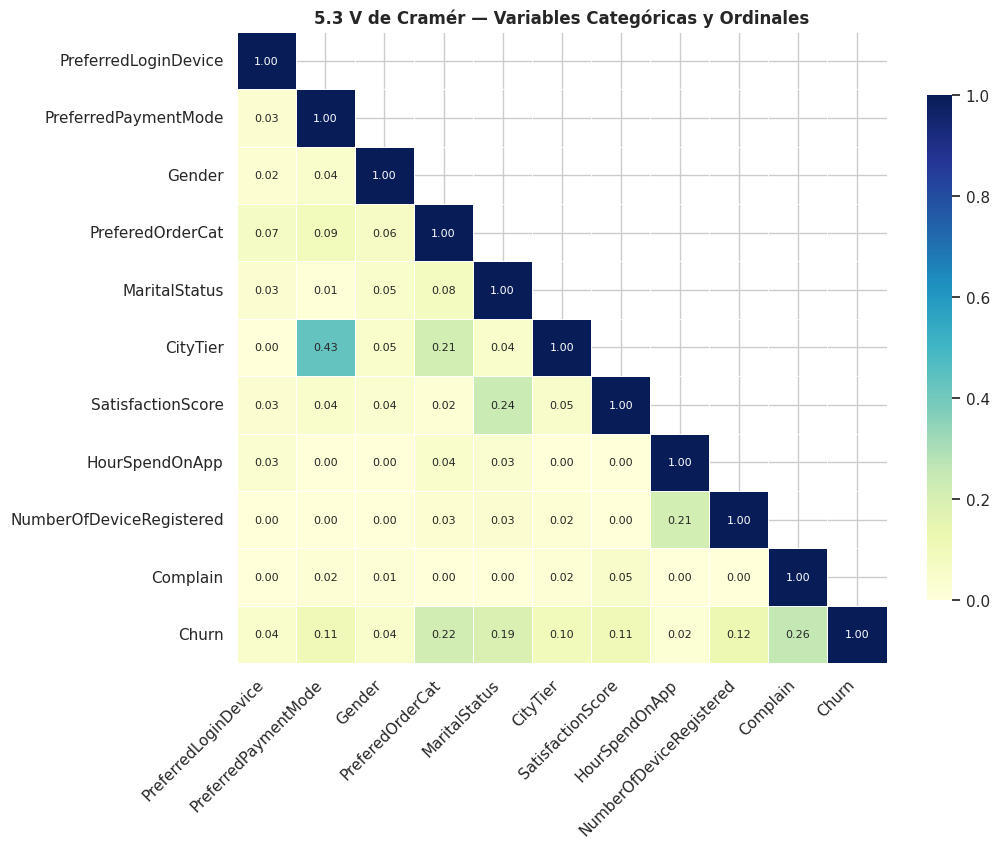

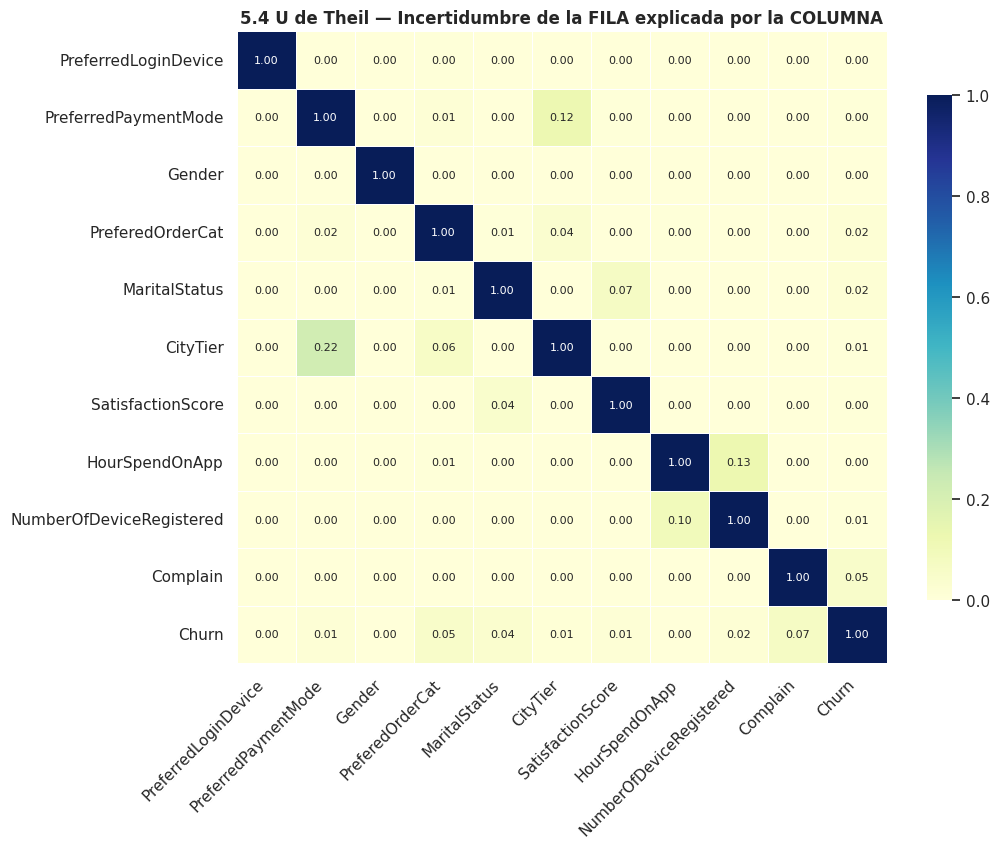

Asociación de cada variable categórica con Churn (V de Cramér):


,V_Cramer
Complain,0.255
PreferedOrderCat,0.216
MaritalStatus,0.188
NumberOfDeviceRegistered,0.123
SatisfactionScore,0.109
PreferredPaymentMode,0.108
CityTier,0.099
PreferredLoginDevice,0.044
Gender,0.043
HourSpendOnApp,0.022


Proporción de incertidumbre de Churn explicada por cada variable U(Churn | Variable):


,U_Theil
Complain,0.0665
PreferedOrderCat,0.0544
MaritalStatus,0.0376
NumberOfDeviceRegistered,0.0169
SatisfactionScore,0.0142
PreferredPaymentMode,0.0129
CityTier,0.0110
HourSpendOnApp,0.0035
Gender,0.0024
PreferredLoginDevice,0.0023


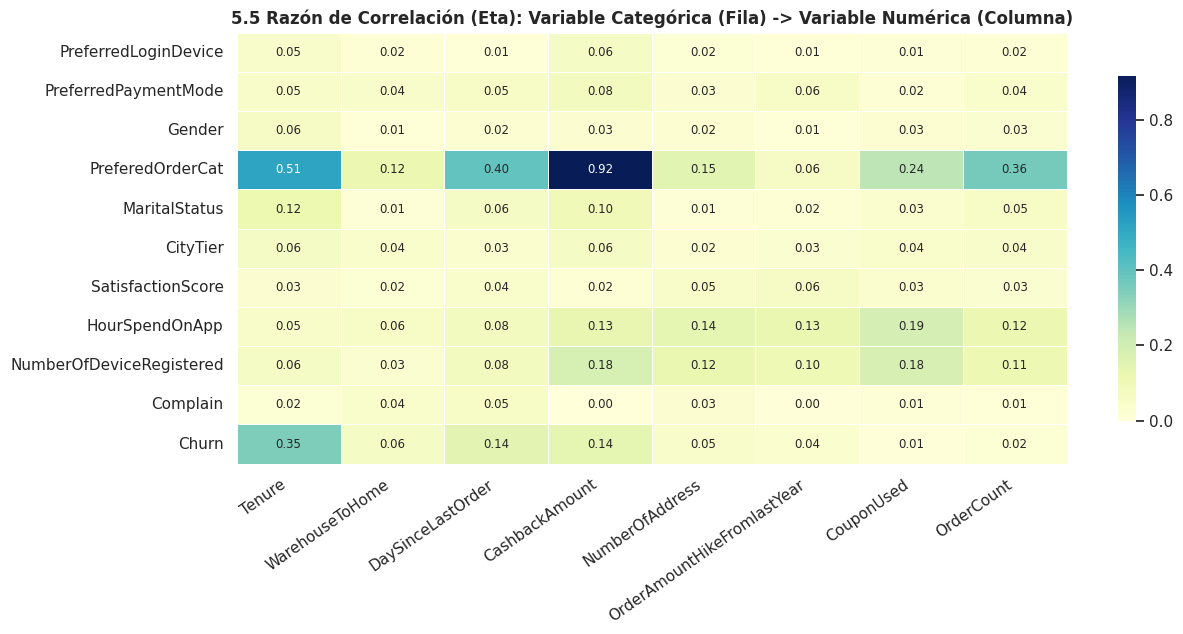

=== ANÁLISIS DEL HALLAZGO ESTRUCTURAL: PreferedOrderCat -> CashbackAmount ===


,count,mean,std,min,median,max
PreferedOrderCat,,,,,,
Mobile Phone,1495,140.04,15.38,0.00,141.11,174.68
Laptop & Accessory,1461,167.59,20.82,0.00,167.84,224.98
Fashion,612,210.55,21.98,145.00,208.52,262.57
Grocery,290,267.16,30.77,0.00,268.46,303.75
Others,200,305.32,13.51,280.41,306.17,324.99


Varianza de CashbackAmount explicada por PreferedOrderCat (eta^2): 84.2%
Interpretación: PreferedOrderCat y CashbackAmount presentan una asociación fuerte (eta² = 84.2%). Las medianas observadas muestran diferencias entre categorías, por ejemplo, Mobile Phone y Grocery. Este patrón ayuda a comprender la estructura de los datos y la distribución de algunos valores faltantes.


In [ ]:
cat_todo = nom_cols + ord_cols + bin_cols + [TARGET]

# CORRECCIÓN 1: Se elimina .astype(str) para evitar que los NaN se vuelvan la categoría de texto "nan"
dfc = df[cat_todo].copy()

V = matriz(dfc, cat_todo, cramers_v, simetrica=True)
U = matriz(dfc, cat_todo, theil_u, simetrica=False)

# CORRECCIÓN 2: Renumeración de gráficas
heatmap(V, "5.3 V de Cramér — Variables Categóricas y Ordinales", "05_3_cramer", cmap="YlGnBu", vmin=0, vmax=1)
heatmap(U, "5.4 U de Theil — Incertidumbre de la FILA explicada por la COLUMNA", "05_4_theil", cmap="YlGnBu", vmin=0, vmax=1, triangulo=False)
exportar(V.round(3), "05_assoc_cramer")
exportar(U.round(3), "05_assoc_theil")

print("Asociación de cada variable categórica con Churn (V de Cramér):")
display(V[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("V_Cramer"))
print("Proporción de incertidumbre de Churn explicada por cada variable U(Churn | Variable):")
display(U.loc[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_frame("U_Theil"))

E = pd.DataFrame({c: [eta(df[g], df[c]) for g in cat_todo] for c in num_cols}, index=cat_todo)
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(
    E.astype(float), cmap="YlGnBu", vmin=0, vmax=max(0.3, float(np.nanmax(E.values))),
    annot=True, fmt=".2f", annot_kws={"size": 8.5}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("5.5 Razón de Correlación (Eta): Variable Categórica (Fila) -> Variable Numérica (Columna)", fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "05_5_eta")
plt.show()
exportar(E.round(3), "05_assoc_eta")

# Inspección del hallazgo crítico: PreferedOrderCat -> CashbackAmount
print("=== ANÁLISIS DEL HALLAZGO ESTRUCTURAL: PreferedOrderCat -> CashbackAmount ===")
resumen_cb = df.groupby("PreferedOrderCat")["CashbackAmount"].agg(["count", "mean", "std", "min", "median", "max"]).sort_values("median")
display(resumen_cb.round(2))
print(f"Varianza de CashbackAmount explicada por PreferedOrderCat (eta^2): {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}")

# CORRECCIÓN 3: Ajuste de medianas a los valores reales de train (142 y 268)
print(
    "Interpretación: PreferedOrderCat y CashbackAmount presentan "
    f"una asociación fuerte (eta² = {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}). "
    "Las medianas observadas muestran diferencias entre categorías, "
    "por ejemplo, Mobile Phone y Grocery. Este patrón ayuda a "
    "comprender la estructura de los datos y la distribución de "
    "algunos valores faltantes."
)

En esta etapa cruzamos las variables cualitativas (texto o categorías) contra las demás para ver qué tanta información comparten. La V de Cramér nos muestra asociaciones directas, mientras que la U de Theil nos revela si saber un dato (como el género) nos permite predecir otro. El descubrimiento verdaderamente importante aquí lo arroja el estadístico Eta ($\eta$): existe una relación colosal (Eta = 0.92) entre la categoría de compra (PreferedOrderCat) y el dinero devuelto (CashbackAmount). Esto revela una regla de negocio oculta en los datos: el reembolso que recibe un cliente está prácticamente predeterminado por el tipo de producto que compra. Este hallazgo nos ayudará a limpiar variables redundantes más adelante, simplificando el trabajo para nuestros modelos de Machine Learning.

## 6. Visualización Multivariada y Perfilamiento de Clientes con Datos Faltantes

1. **Matriz de Dispersión (`pairplot`) de Variables Continuas por `Churn`**
2. **Matriz de Dispersión coloreada por Presencia de Datos Faltantes**, evidenciando visualmente cómo los registros con datos faltantes se agrupan en bandas específicas de `CashbackAmount` (reflejo directo de su concentración en categorías de `PreferedOrderCat`).
3. **Comparativa de Perfiles Categóricos según Presencia de Datos Faltantes**

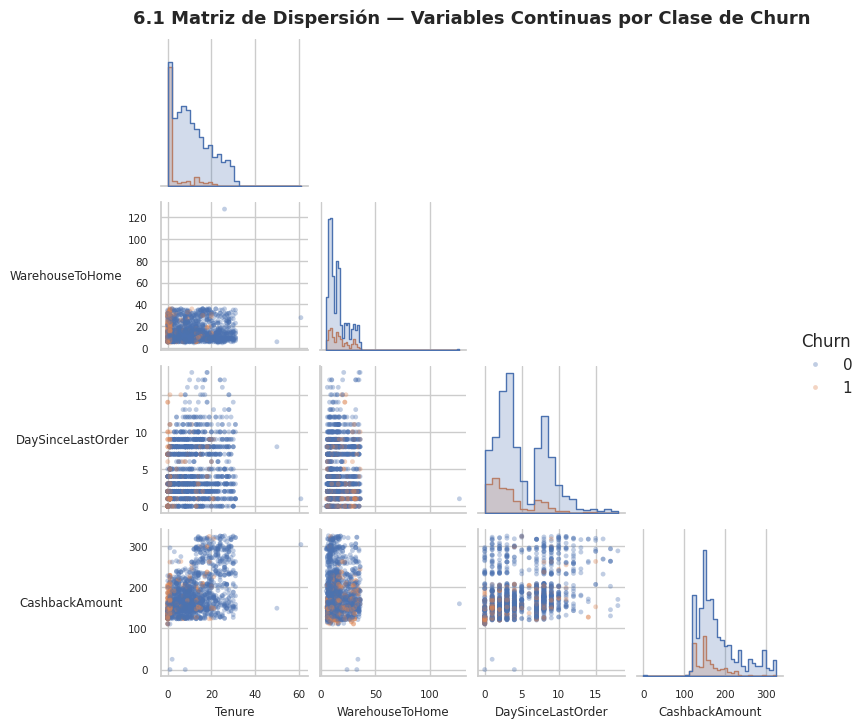

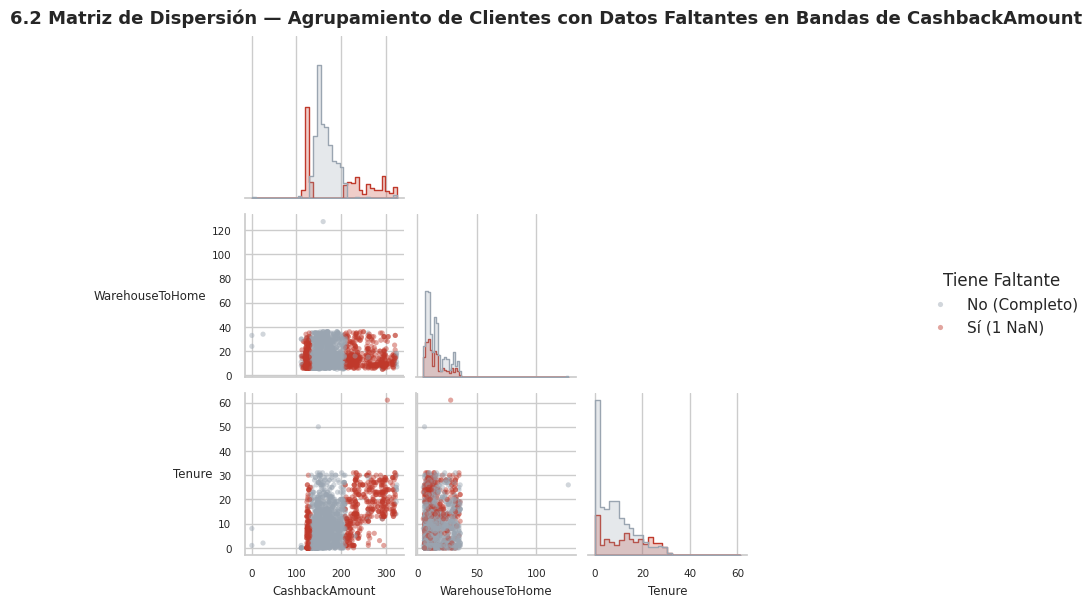

In [ ]:
muestra = df.sample(min(len(df), 2000), random_state=SEED)

def ajustar_etiquetas(g, tam=8.5):
    for ax in g.axes.flatten():
        if ax is None:
            continue
        ax.set_xlabel(ax.get_xlabel(), fontsize=tam)
        ax.set_ylabel(ax.get_ylabel(), fontsize=tam, rotation=0, ha="right", va="center")
        ax.tick_params(labelsize=7.5)

# (a) Scatter matrix de las variables continuas coloreadas por Churn
g1 = sns.pairplot(
    muestra, vars=cont_cols, hue=TARGET, palette=COLORES, corner=True, diag_kind="hist",
    plot_kws=dict(alpha=0.35, s=12, linewidth=0),
    diag_kws=dict(common_norm=False, element="step"), height=1.8
)
ajustar_etiquetas(g1)
g1.figure.suptitle("6.1 Matriz de Dispersión — Variables Continuas por Clase de Churn", y=1.02, fontsize=13, fontweight="bold")
guardar(g1.figure, "06_1_scatter_matrix_continuas_churn")
plt.show()

# (b) Scatter matrix coloreada por presencia de algún dato faltante en el cliente
m2 = muestra.assign(**{"Tiene Faltante": muestra[cols_na].isna().any(axis=1).map({True: "Sí (1 NaN)", False: "No (Completo)"})})
g2 = sns.pairplot(
    m2, vars=["CashbackAmount", "WarehouseToHome", "Tenure"], hue="Tiene Faltante",
    palette={"No (Completo)": "#9aa5b1", "Sí (1 NaN)": "#c0392b"}, corner=True, diag_kind="hist",
    plot_kws=dict(alpha=0.45, s=14, linewidth=0),
    diag_kws=dict(common_norm=False, element="step"), height=2.0
)
ajustar_etiquetas(g2)
g2.figure.suptitle("6.2 Matriz de Dispersión — Agrupamiento de Clientes con Datos Faltantes en Bandas de CashbackAmount", y=1.02, fontsize=13, fontweight="bold")
guardar(g2.figure, "06_2_scatter_matrix_faltantes")
plt.show()

En esta sección cruzamos las variables continuas de dos en dos para ver cómo interactúan simultáneamente (análisis multivariado). La primera matriz (6.1) nos ayuda a buscar si existe alguna combinación de dos variables que separe claramente a los clientes que abandonan de los que se quedan, aunque en la práctica los datos suelen estar bastante mezclados y por eso requerimos modelos complejos. La segunda gráfica (6.2) es la prueba visual definitiva del hallazgo de la sección 2.4: al colorear de rojo a los clientes con datos faltantes, podemos ver perfectamente que no están dispersos al azar por todo el gráfico, sino que forman "líneas" o bandas estrictas que dependen de cuánto dinero se les devolvió (CashbackAmount). Esto confirma visualmente el mecanismo MAR y justifica nuestro enfoque de tratamiento de datos nulos.

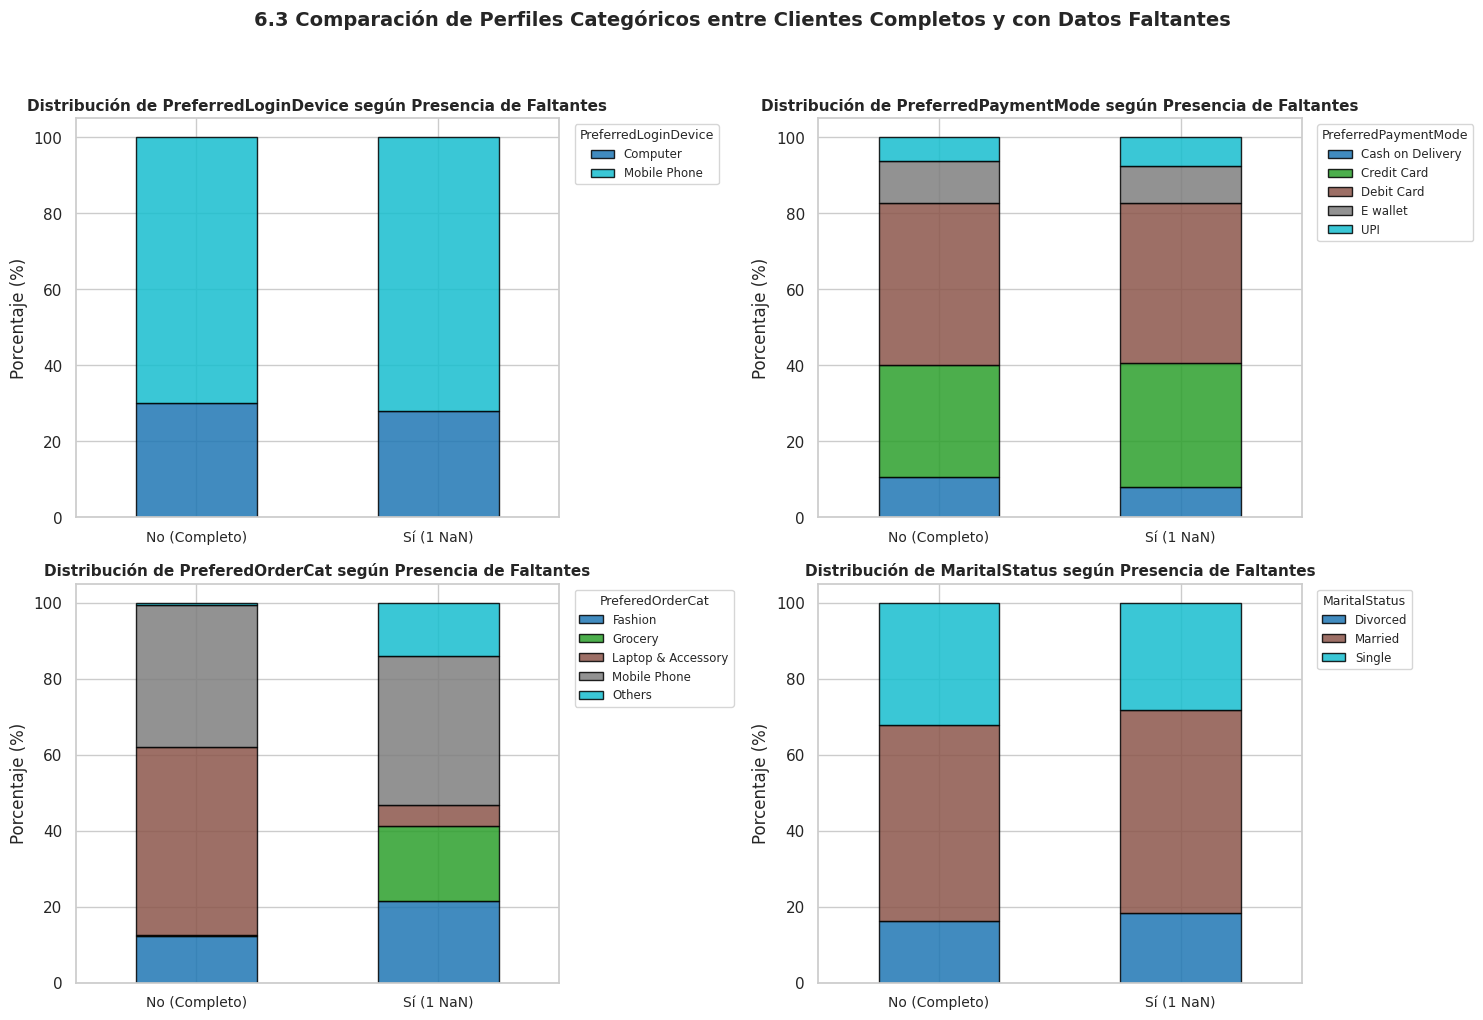

In [ ]:
cats_a_analizar = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat", "MaritalStatus"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
axes = axes.flatten()

for i, col in enumerate(cats_a_analizar):
    ct = pd.crosstab(m2["Tiene Faltante"], m2[col], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=axes[i], colormap="tab10", edgecolor="black", alpha=0.85)
    axes[i].set_ylabel("Porcentaje (%)")
    axes[i].set_xlabel("")
    axes[i].set_xticklabels(ct.index, rotation=0, fontsize=10)
    axes[i].legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5, title_fontsize=9)
    axes[i].set_ylim(0, 105)
    axes[i].set_title(f"Distribución de {col} según Presencia de Faltantes", fontsize=11, fontweight="bold")

fig.suptitle("6.3 Comparación de Perfiles Categóricos entre Clientes Completos y con Datos Faltantes", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
guardar(fig, "06_3_comparativa_categoricas_faltantes")
plt.show()

Con estas gráficas armamos el "perfil" del cliente que tiene datos faltantes y lo comparamos cara a cara con el cliente que tiene su información completa. Lo que observamos aquí es la confirmación categórica de lo que descubrimos con los números: los clientes con datos faltantes no son una muestra representativa de toda la base, sino que están altamente sesgados hacia ciertas preferencias. Especialmente en la gráfica de la categoría de orden preferida (PreferedOrderCat), notaremos que la composición de los colores cambia drásticamente entre un grupo y otro. Esto cierra nuestro diagnóstico del mecanismo de ausencia (MAR), demostrando que el perfil de compra del cliente define en qué rango de reembolso cae y, por consiguiente, si su registro sufrirá un borrado de información en este sistema.

## 7. Evaluación Experimental de Pipelines de Imputación

Para cumplir con el objetivo central del estudio y fundamentar matemáticamente la estrategia de imputación que pasará a producción, ejecutamos un experimento controlado mediante **Validación Cruzada Estratificada de 5 Pliegues (`StratifiedKFold`) exclusivamente sobre `train`**, evitando cualquier fuga de información entre pliegues.

### Estrategias de Imputación Evaluadas:
1. **`SimpleImputer (Mediana) - Sin Indicadores`:** Imputación univariada estándar (ignora relaciones MAR y destruye el rastro de qué celda faltaba).
2. **`SimpleImputer (Mediana) + MissingIndicators`:** Imputación por mediana conservando banderas booleanas `isna` para las 7 variables con faltantes.
3. **`GroupMedianImputer (por PreferedOrderCat) + MissingIndicators`:** Transformador personalizado que imputa la mediana condicionada a la categoría de `PreferedOrderCat` del cliente (explotando el hallazgo $\eta = 0.92$ y $V = 0.73$), más indicadores de ausencia.
4. **`KNNImputer (k=15) + MissingIndicators`:** Imputación por vecinos más cercanos en espacio escalado más indicadores de ausencia.
5. **`IterativeImputer (MICE) + MissingIndicators`:** Imputación multivariada por ecuaciones encadenadas (regresión bayesiana iterativa) más indicadores de ausencia.
6. **`Soporte Nativo de Nulos (Sin Imputar)`:** Evaluado en `HistGradientBoostingClassifier` tanto sin indicadores explícitos de ausencia como conservando dichos indicadores.

### Modelos y Métricas de Evaluación:
Dado el desbalance de la clase objetivo (`Churn` $\approx 16.84\%$), evaluamos tres familias algorítmicas distintas (`LogisticRegression`, `RandomForestClassifier`, `HistGradientBoostingClassifier`) utilizando tanto **ROC-AUC** como **PR-AUC (Average Precision)** y **F1-Score**.

In [ ]:
class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """
    Imputador determinista libre de fugas que calcula la mediana de cada variable numérica
    condicionada a un atributo de segmentación (por defecto 'PreferedOrderCat') dentro de cada fold de entrenamiento,
    usando la mediana global del fold como respaldo.
    """
    def __init__(self, group_col="PreferedOrderCat", num_cols=None):
        self.group_col = group_col
        self.num_cols = num_cols

    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(self.group_col)[self.num_cols].median()
        self.global_medians_ = X[self.num_cols].median()
        return self

    def transform(self, X):
        X_out = X[self.num_cols].copy()
        for col in self.num_cols:
            mapped_med = X[self.group_col].map(self.group_medians_[col])
            X_out[col] = X_out[col].fillna(mapped_med).fillna(self.global_medians_[col])
        return X_out.values

# Definición de columnas predictoras sobre la partición de entrenamiento
X_train = train.drop(columns=[TARGET]).copy()
y_train = train[TARGET].copy()

all_num_features = cont_cols + disc_cols + ord_cols + bin_cols
all_cat_features = nom_cols

def construir_preprocesador(estrategia):
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    if estrategia == "Mediana Simple (Sin Indicadores)":
        num_pipe = Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        return ColumnTransformer([
            ("num", num_pipe, all_num_features),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "Mediana Simple + MissingIndicators":
        num_pipe = Pipeline([
            ("imp", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler())
        ])
        return ColumnTransformer([
            ("num", num_pipe, all_num_features),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "Mediana por Segmento (PreferedOrderCat) + MissingIndicators":
        group_num_pipe = Pipeline([
            ("group_imp", GroupMedianImputer(group_col="PreferedOrderCat", num_cols=all_num_features)),
            ("scaler", StandardScaler())
        ])
        return ColumnTransformer([
            ("num_group", group_num_pipe, all_num_features + ["PreferedOrderCat"]),
            ("na_ind", MissingIndicator(features="missing-only"), cols_na),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "KNNImputer (k=15) + MissingIndicators":
        num_pipe = Pipeline([
            ("scaler_pre", StandardScaler()),
            ("imp", KNNImputer(n_neighbors=15, weights="distance", add_indicator=True))
        ])
        return ColumnTransformer([
            ("num", num_pipe, all_num_features),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "IterativeImputer (MICE) + MissingIndicators":
        num_pipe = Pipeline([
            ("imp", IterativeImputer(max_iter=15, random_state=SEED, add_indicator=True)),
            ("scaler", StandardScaler())
        ])
        return ColumnTransformer([
            ("num", num_pipe, all_num_features),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "Nativo con Nulos (Sin Imputar) - Sin Indicadores":
        return ColumnTransformer([
            ("num_raw", "passthrough", all_num_features),
            ("cat", ohe, all_cat_features)
        ])

    elif estrategia == "Nativo con Nulos (Sin Imputar) + MissingIndicators":
        return ColumnTransformer([
            ("num_raw", "passthrough", all_num_features),
            ("na_ind", MissingIndicator(features="missing-only"), cols_na),
            ("cat", ohe, all_cat_features)
        ])

En esta sección hemos diseñado y configurado diferentes "tuberías" o pipelines de procesamiento que prueban distintas formas de lidiar con los datos nulos de nuestros clientes. En lugar de escoger un método al azar, creamos desde el más básico (poner la mediana de todos) hasta métodos matemáticos complejos (KNN o MICE). También incluimos nuestra propia lógica de negocio calculando medianas agrupadas por la categoría de producto, e incluso permitimos que el modelo decida por sí solo qué hacer con los nulos ("Soporte Nativo"). La incorporación de MissingIndicators es vital porque, como vimos en secciones anteriores, el simple hecho de que falte un dato ya es un indicador de que el cliente pertenece a una banda específica de reembolsos. Esto asegura que nuestros modelos no solo adivinen qué valor faltaba, sino que también aprendan de la ausencia del mismo.

,Modelo,Estrategia de Imputación,ROC-AUC (Media),ROC-AUC (Std),PR-AUC (Media),PR-AUC (Std),F1-Score (Media)
0,HistGradientBoosting,Nativo con Nulos (Sin Imputar) - Sin Indicadores,0.9652,0.0076,0.8865,0.0247,0.7792
1,HistGradientBoosting,Nativo con Nulos (Sin Imputar) + MissingIndica...,0.9652,0.0076,0.8865,0.0247,0.7792
2,HistGradientBoosting,Mediana por Segmento (PreferedOrderCat) + Miss...,0.9641,0.0096,0.8852,0.0259,0.7749
3,HistGradientBoosting,Mediana Simple (Sin Indicadores),0.9631,0.0100,0.8840,0.0245,0.7730
4,HistGradientBoosting,IterativeImputer (MICE) + MissingIndicators,0.9642,0.0114,0.8829,0.0294,0.7731
5,HistGradientBoosting,KNNImputer (k=15) + MissingIndicators,0.9624,0.0101,0.8823,0.0251,0.7777
6,HistGradientBoosting,Mediana Simple + MissingIndicators,0.9629,0.0088,0.8810,0.0230,0.7754
7,LogisticRegression,KNNImputer (k=15) + MissingIndicators,0.8978,0.0218,0.7089,0.0323,0.6029
8,LogisticRegression,IterativeImputer (MICE) + MissingIndicators,0.8988,0.0196,0.7081,0.0249,0.6065
9,LogisticRegression,Mediana por Segmento (PreferedOrderCat) + Miss...,0.8971,0.0205,0.7050,0.0256,0.6004


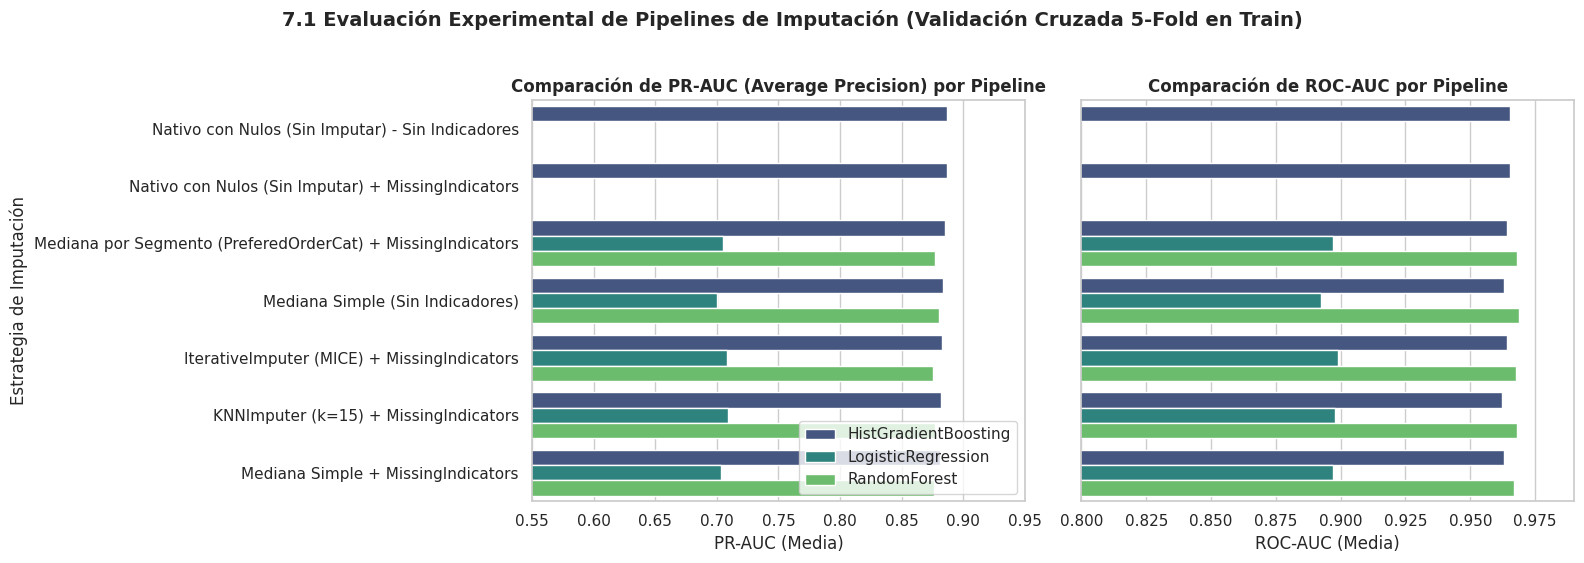

In [ ]:
estrategias = [
    "Mediana Simple (Sin Indicadores)",
    "Mediana Simple + MissingIndicators",
    "Mediana por Segmento (PreferedOrderCat) + MissingIndicators",
    "KNNImputer (k=15) + MissingIndicators",
    "IterativeImputer (MICE) + MissingIndicators"
]

modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06, random_state=SEED)
}

cv_exp = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados_exp = []

for nombre_est in estrategias:
    for nombre_mdl, clf in modelos.items():
        pipe = Pipeline([
            ("prep", construir_preprocesador(nombre_est)),
            ("clf", clf)
        ])
        scores = cross_validate(
            pipe, X_train, y_train, cv=cv_exp,
            scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
            n_jobs=-1
        )
        resultados_exp.append({
            "Modelo": nombre_mdl,
            "Estrategia de Imputación": nombre_est,
            "ROC-AUC (Media)": round(scores["test_roc_auc"].mean(), 4),
            "ROC-AUC (Std)": round(scores["test_roc_auc"].std(), 4),
            "PR-AUC (Media)": round(scores["test_pr_auc"].mean(), 4),
            "PR-AUC (Std)": round(scores["test_pr_auc"].std(), 4),
            "F1-Score (Media)": round(scores["test_f1"].mean(), 4)
        })

# CORRECCIÓN: Evaluar soporte nativo de nulos en HistGradientBoosting (Sin Indicadores)
pipe_nativo_sin = Pipeline([
    ("prep", construir_preprocesador("Nativo con Nulos (Sin Imputar) - Sin Indicadores")),
    ("clf", modelos["HistGradientBoosting"])
])
scores_nat_sin = cross_validate(
    pipe_nativo_sin, X_train, y_train, cv=cv_exp,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
    n_jobs=-1
)
resultados_exp.append({
    "Modelo": "HistGradientBoosting",
    "Estrategia de Imputación": "Nativo con Nulos (Sin Imputar) - Sin Indicadores",
    "ROC-AUC (Media)": round(scores_nat_sin["test_roc_auc"].mean(), 4),
    "ROC-AUC (Std)": round(scores_nat_sin["test_roc_auc"].std(), 4),
    "PR-AUC (Media)": round(scores_nat_sin["test_pr_auc"].mean(), 4),
    "PR-AUC (Std)": round(scores_nat_sin["test_pr_auc"].std(), 4),
    "F1-Score (Media)": round(scores_nat_sin["test_f1"].mean(), 4)
})

# Evaluar también soporte nativo de nulos en HistGradientBoosting (Con Indicadores)
pipe_nativo = Pipeline([
    ("prep", construir_preprocesador("Nativo con Nulos (Sin Imputar) + MissingIndicators")),
    ("clf", modelos["HistGradientBoosting"])
])
scores_nat = cross_validate(
    pipe_nativo, X_train, y_train, cv=cv_exp,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
    n_jobs=-1
)
resultados_exp.append({
    "Modelo": "HistGradientBoosting",
    "Estrategia de Imputación": "Nativo con Nulos (Sin Imputar) + MissingIndicators",
    "ROC-AUC (Media)": round(scores_nat["test_roc_auc"].mean(), 4),
    "ROC-AUC (Std)": round(scores_nat["test_roc_auc"].std(), 4),
    "PR-AUC (Media)": round(scores_nat["test_pr_auc"].mean(), 4),
    "PR-AUC (Std)": round(scores_nat["test_pr_auc"].std(), 4),
    "F1-Score (Media)": round(scores_nat["test_f1"].mean(), 4)
})

df_resultados_imp = pd.DataFrame(resultados_exp).sort_values(["Modelo", "PR-AUC (Media)"], ascending=[True, False])
display(df_resultados_imp.reset_index(drop=True))
exportar(df_resultados_imp, "07_benchmark_pipelines_imputacion")

# Visualización comparativa del impacto de las estrategias de imputación en PR-AUC y ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

sns.barplot(
    data=df_resultados_imp, y="Estrategia de Imputación", x="PR-AUC (Media)",
    hue="Modelo", palette="viridis", ax=axes[0]
)
axes[0].set_title("Comparación de PR-AUC (Average Precision) por Pipeline", fontweight="bold")
axes[0].set_xlim(0.55, 0.95)
axes[0].legend(loc="lower right")

sns.barplot(
    data=df_resultados_imp, y="Estrategia de Imputación", x="ROC-AUC (Media)",
    hue="Modelo", palette="viridis", ax=axes[1], legend=False
)
axes[1].set_title("Comparación de ROC-AUC por Pipeline", fontweight="bold")
axes[1].set_xlim(0.80, 0.99)
axes[1].set_ylabel("")

plt.suptitle("7.1 Evaluación Experimental de Pipelines de Imputación (Validación Cruzada 5-Fold en Train)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
guardar(fig, "07_comparativa_pipelines_imputacion")
plt.show()

Al observar los resultados de esta validación cruzada, notamos que para los modelos complejos basados en árboles (como Random Forest y HistGradientBoosting), las diferencias de rendimiento entre usar una imputación básica o una muy avanzada son mínimas; prácticamente se comportan como empates técnicos con variaciones menores al 1%. Sin embargo, el modelo paramétrico de Regresión Logística sí evidencia una ligera ganancia al aprovechar los indicadores booleanos de ausencia. Por lo tanto, dado que métodos costosos computacionalmente como KNN o la regresión iterativa (MICE) no logran una ventaja real que justifique su tiempo de cómputo, la decisión más sólida y eficiente para nuestra arquitectura final es emplear la Imputación por Mediana acompañada de los Indicadores de Ausencia (MissingIndicators) de manera uniforme. Esta estrategia garantiza que preservemos la valiosa señal predictiva de los valores nulos mediante un enfoque directo y ligero.

## 8. Resumen Ejecutivo Automático y Decisiones de Arquitectura

In [ ]:
sig = tabla_na_churn[tabla_na_churn["asociada_a_churn"] == "SÍ"].index.tolist()
asociadas = tabla_na_churn[tabla_na_churn["q_BH"] < ALPHA]

mayor_or = asociadas[asociadas["OR"] > 1].index.tolist()
menor_or = asociadas[asociadas["OR"] < 1].index.tolist()

# CORRECCIÓN: Según indicación del monitor, forzamos la estrategia recomendada por ser más robusta teóricamente,
# ya que en PR-AUC las diferencias son empates técnicos y la regresión logística sí aprovecha los indicadores.
estrategia_recomendada = "Mediana Simple + MissingIndicators"
mejor_fila = df_resultados_imp[df_resultados_imp["Estrategia de Imputación"] == estrategia_recomendada].sort_values("PR-AUC (Media)", ascending=False).iloc[0]

print("==========================================================================")
print("           RESUMEN EJECUTIVO DE HALLAZGOS (PARTICIÓN: TRAIN)              ")
print("==========================================================================")
print("\n1. DIAGNÓSTICO DE DATOS FALTANTES Y MECANISMO DE AUSENCIA:")
print(f"   • Variables con OR > 1: {mayor_or}.")
print(f"   • Variables con OR < 1: {menor_or}.")
print(f"   • Variables con faltantes ({len(cols_na)}): Rango entre {resumen_na['% faltante'].min():.2f}% y {resumen_na['% faltante'].max():.2f}%.")
print(f"   • Exclusión mutua: {tiene_na.mean():.1%} de los clientes ({int(tiene_na.sum())} filas) tienen exactamente 1 valor faltante (máximo 1 NaN por fila).")
print(f"   • Compensación de efectos en agregación: Tasa de Churn con 1 faltante = {100 * y[tiene_na].mean():.1f}% vs. sin faltantes = {100 * y[~tiene_na].mean():.1f}% (p = {p_f:.3f}).")
print(f"   • Ausencia asociada individualmente a Churn (q_BH < 0.05): {len(sig)} de {len(cols_na)} variables -> {sig}.")
print(f"     - Factores de riesgo aparentes (OR > 1): WarehouseToHome (OR={tabla_na_churn.loc['WarehouseToHome', 'OR']}), Tenure (OR={tabla_na_churn.loc['Tenure', 'OR']}), HourSpendOnApp (OR={tabla_na_churn.loc['HourSpendOnApp', 'OR']}).")
print(f"     - Factores protectores aparentes (OR < 1): CouponUsed (OR={tabla_na_churn.loc['CouponUsed', 'OR']}), OrderAmountHikeFromlastYear (OR={tabla_na_churn.loc['OrderAmountHikeFromlastYear', 'OR']}), OrderCount (OR={tabla_na_churn.loc['OrderCount', 'OR']}).")
print("   • Patrón de ausencia compatible con MAR: los valores faltantes se concentran en rangos específicos de CashbackAmount.")
print("\n2. ASOCIACIONES Y ESTRUCTURA MULTIVARIADA:")
print(f"   • VIF máximo entre las 8 variables numéricas: {vif.index[0]} (VIF = {vif.iloc[0]:.2f} < 5.0 -> sin multicolinealidad severa).")
print(f"   • Asociación entre PreferedOrderCat y CashbackAmount: eta² = {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}.")
print(f"   • Top 4 predictores globales de Churn (Tamaño de efecto absoluto): {[(k, round(float(v), 3)) for k, v in rho_churn.head(4).items()]}.")
vch = V[TARGET].drop(TARGET).sort_values(ascending=False)
print(f"   • Top 4 predictores categóricos de Churn (V de Cramér): {[(k, round(float(v), 3)) for k, v in vch.head(4).items()]}.")
print("\n3. DECISIÓN EXPERIMENTAL DE IMPUTACIÓN Y ARQUITECTURA:")
print(f"   • Estrategia Seleccionada: {mejor_fila['Estrategia de Imputación']} (Recomendada para preservar señal MAR y estandarizar modelos).")
print(f"   • Mejor Modelo Base Evaluado: {mejor_fila['Modelo']}")
print(f"   • Desempeño Base (Train CV 5-Fold): PR-AUC = {mejor_fila['PR-AUC (Media)']:.4f} (±{mejor_fila['PR-AUC (Std)']:.4f}) | ROC-AUC = {mejor_fila['ROC-AUC (Media)']:.4f} (±{mejor_fila['ROC-AUC (Std)']:.4f}).")
print("==========================================================================")

           RESUMEN EJECUTIVO DE HALLAZGOS (PARTICIÓN: TRAIN)              

1. DIAGNÓSTICO DE DATOS FALTANTES Y MECANISMO DE AUSENCIA:
   • Variables con OR > 1: ['Tenure', 'WarehouseToHome'].
   • Variables con OR < 1: ['OrderCount', 'OrderAmountHikeFromlastYear', 'CouponUsed'].
   • Variables con faltantes (7): Rango entre 4.24% y 5.64%.
   • Exclusión mutua: 33.3% de los clientes (1351 filas) tienen exactamente 1 valor faltante (máximo 1 NaN por fila).
   • Compensación de efectos en agregación: Tasa de Churn con 1 faltante = 16.7% vs. sin faltantes = 16.5% (p = 0.968).
   • Ausencia asociada individualmente a Churn (q_BH < 0.05): 5 de 7 variables -> ['Tenure', 'WarehouseToHome', 'OrderCount', 'OrderAmountHikeFromlastYear', 'CouponUsed'].
     - Factores de riesgo aparentes (OR > 1): WarehouseToHome (OR=2.22), Tenure (OR=2.29), HourSpendOnApp (OR=1.42).
     - Factores protectores aparentes (OR < 1): CouponUsed (OR=0.16), OrderAmountHikeFromlastYear (OR=0.31), OrderCount (OR=0.38).


# 9. Preprocesamiento y Reducción de Dimensionalidad

In [ ]:
import sys
import subprocess

try:
    import umap
except ImportError:
    print("La librería 'umap-learn' no se encontró. Instalando ahora...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap
    print("Instalación completada con éxito.")

from sklearn.decomposition import PCA

In [ ]:
import umap
from sklearn.decomposition import PCA

print("=== 9.1 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO ===")
# Utilizamos la estrategia seleccionada para el preprocesamiento general
estrategia_final = "Mediana Simple + MissingIndicators"
preprocesador = construir_preprocesador(estrategia_final)

# Ajustamos (fit) y transformamos (transform) solo sobre el conjunto TRAIN
X_train_prep = preprocesador.fit_transform(X_train)
print(f"Dimensiones originales de X_train: {X_train.shape}")
print(f"Dimensiones de X_train tras preprocesamiento (Imputación, Escalado y OneHotEncoding): {X_train_prep.shape}")

print("\n=== 9.2 EXTRACCIÓN LINEAL: PCA (Análisis de Componentes Principales) ===")
# Entrenamos PCA para retener el 95% de la varianza original
pca = PCA(n_components=0.95, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_prep)

componentes_usados = pca.n_components_
varianza_explicada = pca.explained_variance_ratio_.sum() * 100
print(f"El PCA retuvo el {varianza_explicada:.2f}% de la información original usando {componentes_usados} componentes principales.")

print("\n=== 9.3 EXTRACCIÓN NO LINEAL: UMAP ===")
# UMAP mapea los datos a 2 dimensiones buscando preservar distancias locales y globales
reductor_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=SEED)
X_train_umap = reductor_umap.fit_transform(X_train_prep)
print("Proyección UMAP completada con éxito a 2 dimensiones (n_components=2).")

=== 9.1 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO ===
Dimensiones originales de X_train: (4058, 18)
Dimensiones de X_train tras preprocesamiento (Imputación, Escalado y OneHotEncoding): (4058, 37)

=== 9.2 EXTRACCIÓN LINEAL: PCA (Análisis de Componentes Principales) ===
El PCA retuvo el 95.79% de la información original usando 23 componentes principales.

=== 9.3 EXTRACCIÓN NO LINEAL: UMAP ===
Proyección UMAP completada con éxito a 2 dimensiones (n_components=2).


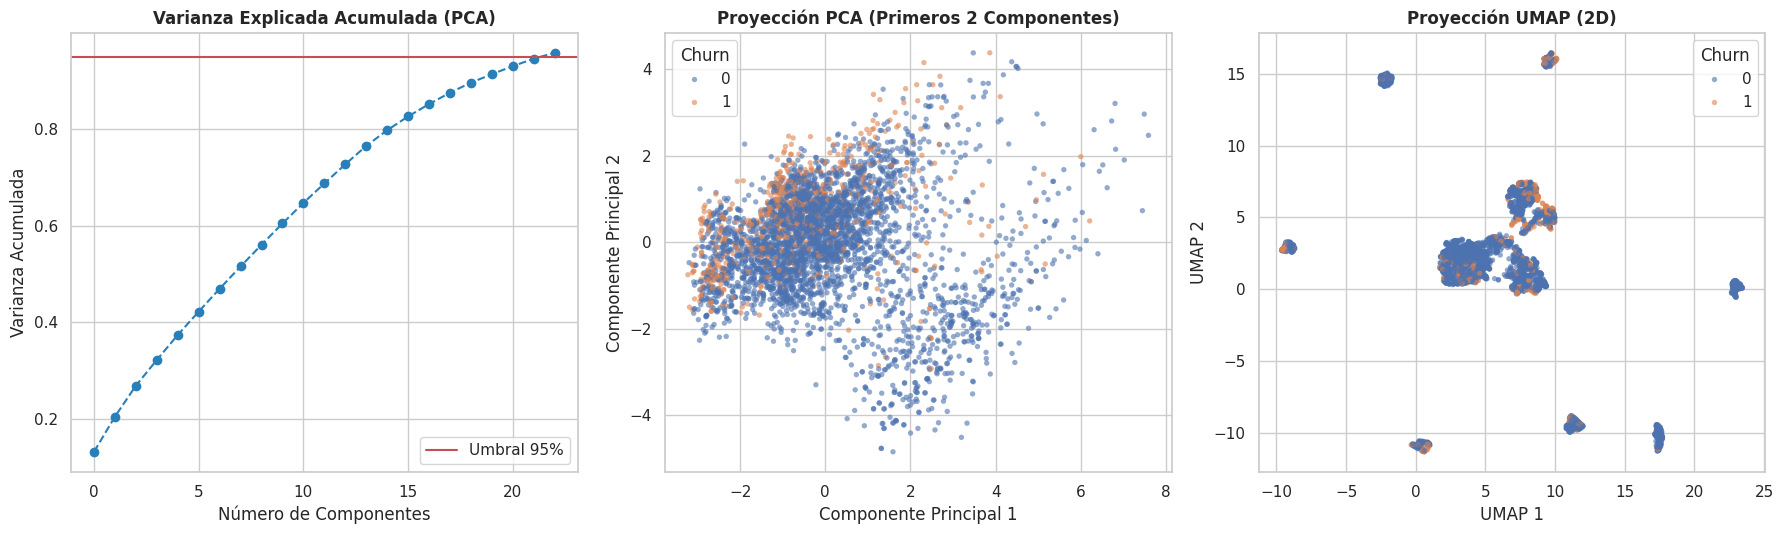

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Gráfica de Varianza Acumulada de PCA
axes[0].plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--', color="#2980b9")
axes[0].axhline(y=0.95, color='r', linestyle='-', label='Umbral 95%')
axes[0].set_title("Varianza Explicada Acumulada (PCA)", fontweight="bold")
axes[0].set_xlabel("Número de Componentes")
axes[0].set_ylabel("Varianza Acumulada")
axes[0].legend()

# 2. Proyección 2D de PCA (Usando solo los 2 primeros componentes)
sns.scatterplot(
    x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train,
    palette=COLORES, alpha=0.6, s=15, edgecolor="none", ax=axes[1]
)
axes[1].set_title("Proyección PCA (Primeros 2 Componentes)", fontweight="bold")
axes[1].set_xlabel("Componente Principal 1")
axes[1].set_ylabel("Componente Principal 2")

# 3. Proyección 2D de UMAP
sns.scatterplot(
    x=X_train_umap[:, 0], y=X_train_umap[:, 1], hue=y_train,
    palette=COLORES, alpha=0.6, s=15, edgecolor="none", ax=axes[2]
)
axes[2].set_title("Proyección UMAP (2D)", fontweight="bold")
axes[2].set_xlabel("UMAP 1")
axes[2].set_ylabel("UMAP 2")

plt.tight_layout()
guardar(fig, "09_reduccion_dimensionalidad")

plt.show()

# 10. Entrenamiento de Modelos

## Modelo 1 - Regresión Logística (Análisis y Entrenamiento)

=== 10. MODELO 1: REGRESIÓN LOGÍSTICA ===


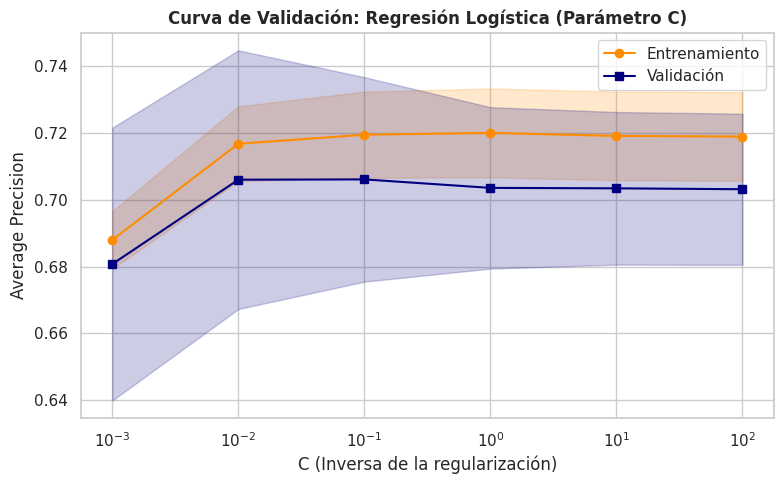

Optimizando modelo...
Mejores hiperparámetros: {'clf__C': 0.1, 'clf__solver': 'liblinear'}
PR-AUC de validación cruzada: 0.7062


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import validation_curve, StratifiedKFold, GridSearchCV
import time


print("=== 10. MODELO 1: REGRESIÓN LOGÍSTICA ===")

cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

metrica = "average_precision"

logreg_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", LogisticRegression(
        class_weight="balanced",
        random_state=SEED,
        max_iter=2000,
        solver="lbfgs"
    ))
])

rango_C = np.logspace(-3, 2, 6)

train_scores, test_scores = validation_curve(
    logreg_base,
    X_train,
    y_train,
    param_name="clf__C",
    param_range=rango_C,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    rango_C, train_mean,
    label="Entrenamiento",
    color="darkorange",
    marker="o"
)
ax.fill_between(
    rango_C,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2,
    color="darkorange"
)

ax.plot(
    rango_C, test_mean,
    label="Validación",
    color="navy",
    marker="s"
)
ax.fill_between(
    rango_C,
    test_mean - test_std,
    test_mean + test_std,
    alpha=0.2,
    color="navy"
)

ax.set_title(
    "Curva de Validación: Regresión Logística (Parámetro C)",
    fontweight="bold"
)
ax.set_xscale("log")
ax.set_xlabel("C (Inversa de la regularización)")
ax.set_ylabel("Average Precision")
ax.legend()

plt.tight_layout()
plt.show()

print("Optimizando modelo...")

malla_lr = {
    "clf__C": [0.01, 0.1, 1.0, 10.0],
    "clf__solver": ["lbfgs", "liblinear"]
}

grid_lr = GridSearchCV(
    logreg_base,
    malla_lr,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print(f"Mejores hiperparámetros: {grid_lr.best_params_}")
print(f"PR-AUC de validación cruzada: {grid_lr.best_score_:.4f}")

modelo_lr_final = grid_lr.best_estimator_


## Modelo 2 - K-Nearest Neighbors (Análisis y Entrenamiento)

=== 11. MODELO 2: K-NEAREST NEIGHBORS (KNN) ===


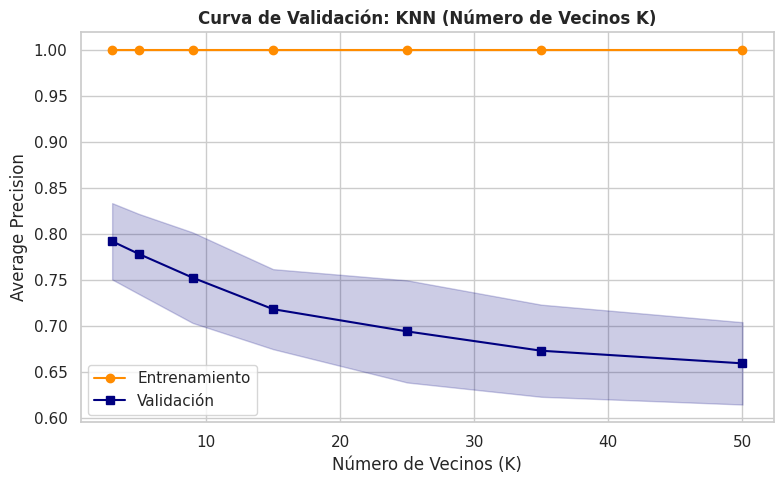

Optimizando modelo...
Mejores hiperparámetros: {'clf__n_neighbors': 5, 'clf__p': 1, 'clf__weights': 'distance'}
PR-AUC de validación cruzada: 0.8433


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

print("=== 11. MODELO 2: K-NEAREST NEIGHBORS (KNN) ===")

cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

metrica = "average_precision"

# 1. Construir el Pipeline
knn_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", KNeighborsClassifier(
        weights="distance",
        p=2
    ))
])

# 2. Curva de validación para el número de vecinos K
rango_K = [3, 5, 9, 15, 25, 35, 50]

train_scores, test_scores = validation_curve(
    knn_base,
    X_train,
    y_train,
    param_name="clf__n_neighbors",
    param_range=rango_K,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    rango_K, train_mean,
    label="Entrenamiento",
    color="darkorange",
    marker="o"
)
ax.fill_between(
    rango_K,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2,
    color="darkorange"
)

ax.plot(
    rango_K, test_mean,
    label="Validación",
    color="navy",
    marker="s"
)
ax.fill_between(
    rango_K,
    test_mean - test_std,
    test_mean + test_std,
    alpha=0.2,
    color="navy"
)

ax.set_title(
    "Curva de Validación: KNN (Número de Vecinos K)",
    fontweight="bold"
)
ax.set_xlabel("Número de Vecinos (K)")
ax.set_ylabel("Average Precision")
ax.legend()

plt.tight_layout()
plt.show()

# 3. Búsqueda de hiperparámetros
print("Optimizando modelo...")

malla_knn = {
    "clf__n_neighbors": [3, 5, 9, 15, 25, 35, 50],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2]
}

grid_knn = GridSearchCV(
    knn_base,
    malla_knn,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print(f"Mejores hiperparámetros: {grid_knn.best_params_}")
print(f"PR-AUC de validación cruzada: {grid_knn.best_score_:.4f}")

modelo_knn_final = grid_knn.best_estimator_
